# ขั้นที่ 8: ทดลอง feature engineering — งานที่ 1 (ชื่อวิทยาศาสตร์ / ยุค)

ต่อยอดระบบของ notebook 11 (feature ที่ไม่รั่ว + สลับโมเดลตามกรณี + ตัวกรองความสอดคล้องทางอนุกรมวิธาน) โดยเพิ่มกลุ่ม feature ทีละกลุ่ม

| กลุ่ม | feature | หมายเหตุกันรั่ว |
|---|---|---|
| `formation_flag` / `formation_only` | `FORMATION`, `GEO_GROUP` จากตาราง notebook 07 แบบ Impute+Flag vs Impute only + อายุ / ชนิดหินของหมวดหินจาก [ThaiLex](https://thailex.geolex.org/) | ไม่ใช้คอลัมน์ `target_*`, `ref_*`, `merge_confidence` ของ notebook 07 และไม่ใช้ส่วน Fossils ของ ThaiLex |
| `fpart` | `f_part` (991 ค่า) → หมวดส่วนของซาก + flag หลายป้าย | — |
| `tfidf` / `bert` / `mlm` | ตัวแทนข้อความของ `com_name_generic | f_type | f_part`: TF-IDF char n-gram, **WangchanBERTa** (BERT ภาษาไทย), multilingual MiniLM → ลดเหลือ 32 มิติ (fit ต่อ fold) | ใช้ `com_name_generic` (ไม่ใช่ `com_name` ที่รั่ว) |
| `context` | สัดส่วนสกุลที่พบแล้วในแหล่งเดียวกัน และแหล่งใกล้เคียง ≤ 50 กม. (ถ่วงระยะ) + ยุคที่ ทธ. บันทึกของแหล่ง | **out-of-fold ซ้อน**: แถวทดสอบใช้ตัวอย่างใน fold train; แถว train ใช้ fold อื่นที่ไม่ใช่ทั้งของตัวเองและ fold ทดสอบ (กัน target leakage ของ target encoding); ไม่ใช้ยุคที่เติม (เติมจากชื่อสกุล) |
| `pbdb` | จำนวน occurrence ของแต่ละสกุลใน PBDB ภายใน 25 / 50 กม. ของแหล่ง | ตัด collection PBDB ที่อยู่ < 2 กม. จากแหล่ง (อาจเป็นตัวอย่างชุดเดียวกัน) |

**การวัดผล**: เส้นทาง "แหล่งเดิม" ใช้ CV `random` (โมเดลฐาน xgb ทุก feature), เส้นทาง "แหล่งใหม่" ใช้ `spatial_block` (โมเดลฐาน lgbm ข้อมูลตัวอย่าง)
คัดกรองด้วย LightGBM แบบเร็ว (`lgbm_fast`) แล้วรวมกลุ่มที่ช่วยเป็นชุดสุดท้ายด้วยโมเดลเต็ม; รายงานทั้งก่อน/หลังตัวกรองความสอดคล้อง

**ยุค**: `FORMATION` ที่ ทธ. บันทึกมีใน 84% ของแหล่งที่บันทึกยุค แต่มีแค่ 9% ของแหล่งที่ต้องเติมยุค (บันทึกมาคู่กัน) → วัด 2 แบบ:
ใช้ตามที่บันทึก (มองโลกในแง่ดี) และซ่อน `FORMATION` ของแหล่งทดสอบ (เหมือนใช้จริง); ทางเลือกหลักคือหมวดหินจาก**แผนที่ธรณี**ที่ตำแหน่งแหล่ง (มีทุกแหล่ง)

**รันต่อได้**: ผลทุก (การทดลอง, fold) อยู่ใน `models/task1/FE/`; embedding ข้อความ cache ใน `data/features/text_emb/`

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml
import feature_lib as fl

import json
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import BallTree

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
ml.seed_everything(42)
OUT = ml.MODELS / "task1" / "FE"
OUT.mkdir(parents=True, exist_ok=True)
T2 = ml.MODELS / "task2" / "final"

## 1. ข้อมูลฐาน (เหมือน notebook 11)

In [2]:
allf = pd.read_parquet(ml.FEAT / "all_features.parquet").merge(pd.read_parquet(ml.FEAT / "folds.parquet"), on="point_id")
meta2 = json.loads((T2 / "final_meta.json").read_text(encoding="utf-8"))
CAT_SITE = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind"]
for c in CAT_SITE + ["oc_nearest_rock"]:
    allf[c] = allf[c].astype(str)
SITE_NUM, SITE_CAT = meta2["features"]["num"], [c for c in meta2["features"]["cat"] if c in CAT_SITE]
sites = allf[allf.source.eq("dmr_site")].copy()
sites["oid"] = sites.point_id.str[4:].astype(int)
st1 = pd.read_parquet(ml.FEAT / "site_task1_features.parquet")              # ประเภทซากในแหล่ง + CNN PCA ตัวจริง (notebook 11)
TYPE_COLS = [c for c in st1.columns if c.startswith("type_")]
EMB_COLS = [c for c in st1.columns if c.startswith("cnn_pc")]
sites = sites.merge(st1.drop(columns=["oid"] + EMB_COLS), on="point_id", how="left")
EMB = {(cv, k): pd.read_parquet(ml.MODELS / "task1" / "emb" / f"{cv}__f{k}.parquet") for cv in ml.CV_SCHEMES for k in range(ml.N_FOLDS)}

spec = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
spec["taxon"] = spec.sci_name.map(fl.parse_taxon)
spec["genus_true"] = spec.taxon.map(lambda t: t[0] if t else None)
spec["species_true"] = spec.taxon.map(lambda t: t[1] if t else None)
S = spec.merge(sites.drop(columns=["source", "ref_id"]).rename(columns={"oid": "site_OBJECTID"}).assign(
    site_OBJECTID=lambda d: d.site_OBJECTID.astype("Int64")), on="site_OBJECTID", how="left")
S["point_id"] = S.fossil_id
rng = np.random.default_rng(42)
S["fold_random"] = rng.integers(0, ml.N_FOLDS, len(S))
for sc in ["site_cluster", "spatial_block"]:
    S[f"fold_{sc}"] = S[f"fold_{sc}"].fillna(pd.Series(rng.integers(0, ml.N_FOLDS, len(S)), index=S.index)).astype(int)
    S[f"group_{sc}"] = S[f"group_{sc}"].astype(object).where(S[f"group_{sc}"].notna(), "nosite_" + S.fossil_id)
COM_VOCAB = sorted(set(S.loc[S.genus_true.isna(), "com_name"].dropna()))
S["com_name_generic"] = S.com_name.where(S.com_name.isin(COM_VOCAB), S.f_type)
SPEC_CAT = ["com_name_generic", "f_type", "f_group", "f_part", "province", "district"]
for c in SPEC_CAT + SITE_CAT:
    S[c] = S[c].astype(str)
S["groups"] = [fl.specimen_classes(t, c) for t, c in zip(S.f_type, S.com_name_generic)]
lab = S[S.genus_true.notna()].reset_index(drop=True)
gc = lab.genus_true.value_counts()
GENERA = sorted(gc[gc >= 5].index) + ["อื่น ๆ"]
lab["genus_cls"] = lab.genus_true.where(lab.genus_true.isin(GENERA), "อื่น ๆ")
YG = lab.genus_cls.map({g: i for i, g in enumerate(GENERA)}).values
TOPG = [g for g in lab.genus_cls.value_counts().index if g != "อื่น ๆ"][:40]
print(f"ตัวอย่างมีสกุล {len(lab):,} | คลาส {len(GENERA)} | สกุลที่ใช้เป็น feature บริบท {len(TOPG)}")

ตัวอย่างมีสกุล 3,944 | คลาส 132 | สกุลที่ใช้เป็น feature บริบท 40


## 2. สร้าง feature กลุ่มใหม่

In [3]:
# ---- หมวดหิน / กลุ่มหิน (notebook 07) + ThaiLex
P_RANK = {p: i for i, p in enumerate(fl.PERIOD_ORDER)}
TL_PERIOD = {"Neogene": "Tertiary", "Paleogene": "Tertiary", "Neoproterozoic": "Precambrian"}


def thailex_feats(name):
    m = fl.thailex_match(name) if isinstance(name, str) and name not in ("Unknown", "nan") else None
    if m is None:
        return {"fm_matched": 0}
    per = [TL_PERIOD.get(p.strip(), p.strip()) for p in str(m.period).split(",")]
    ranks = [P_RANK[p] for p in per if p in P_RANK]
    return {"fm_matched": 1, "fm_rank_old": min(ranks) if ranks else np.nan, "fm_rank_young": max(ranks) if ranks else np.nan,
            **{f"fm_{k}": v for k, v in fl.lithology_flags(f"{m.lithology} {m.lithology_pattern}").items()}}


FM = {}
for variant, f in [("formation_flag", "specimens_impute_flag.csv"), ("formation_only", "specimens_impute_only.csv")]:
    t = pd.read_csv(ml.DATA / "processed" / "model" / f, dtype={"fossil_id": str}, encoding="utf-8-sig", low_memory=False)
    keep = ["fossil_id", "FORMATION", "GEO_GROUP"] + ([c for c in ["formation_missing", "geo_group_missing", "has_locality", "coord_imputed"] if c in t] if variant == "formation_flag" else [])
    t = t[keep].copy()
    tl = pd.DataFrame([thailex_feats(n) for n in t.FORMATION], index=t.index)
    FM[variant] = pd.concat([t, tl], axis=1).rename(columns={"FORMATION": "fm_FORMATION", "GEO_GROUP": "fm_GEO_GROUP"})
    for c in ["fm_FORMATION", "fm_GEO_GROUP"]:
        FM[variant][c] = FM[variant][c].astype(str)
print("จับคู่หมวดหินกับ ThaiLex ได้:", f"{FM['formation_flag'].fm_matched.mean():.0%} ของตัวอย่าง",
      f"({FM['formation_flag'].loc[FM['formation_flag'].fm_FORMATION.ne('Unknown'), 'fm_matched'].mean():.0%} ของที่มีหมวดหิน)")

# ---- ส่วนของซาก
PART_RULES = [("สันหลัง", r"สันหลัง|vertebra|cervical|dorsal|centrum|sacral"), ("หาง", r"หาง|caudal"), ("ซี่โครง", r"ซี่โครง|rib"),
              ("เชฟรอน", r"เชฟรอน|chevron"), ("ฟัน", r"ฟัน|tooth|teeth"), ("กะโหลก", r"กะโหลก|กระโหลก|ขากรรไกร|skull|mandible|jaw|dentary|maxilla"),
              ("แขนขา", r"ต้นขา|ต้นแขน|แข้ง|ปลายแขน|femur|humerus|tibia|fibula|ulna|radius|limb|สะบัก|เชิงกราน|pelvis|ilium|ischium|pubis|scapula"),
              ("นิ้วเท้า", r"นิ้ว|เท้า|ข้อเท้า|ฝ่า|กีบ|เล็บ|claw|phalan|metatars|metacarp"), ("กระดอง", r"กระดอง|plastron|carapace"),
              ("เกล็ด", r"เกล็ด|scale|ganoid"), ("เปลือก", r"เปลือก|shell|ฝา"),
              ("โครงร่างแข็ง", r"ปะการัง|ไครนอยด์|ก้าน|โครงสร้างแข็ง|calyx|stem|ossicle|โคโลนี"),
              ("รอย", r"รอยตีน|รอย|footprint|trace|burrow"), ("พืช", r"ใบ|ลำต้น|เนื้อไม้|ไม้|เมล็ด|leaf|wood|seed|plant|สาหร่าย"),
              ("ไข่", r"ไข่|egg"), ("กระดูกอื่น", r"กระดูก|bone"), ("ทั้งตัว", r"ทั้งตัว|complete|โครงกระดูก|ทั้งหมด")]


def part_feats(t):
    t = str(t).lower()
    hits = [n for n, p in PART_RULES if re.search(p, t)]
    return {"part_cat": hits[0] if hits else ("ไม่ระบุ" if t in ("nan", "") else "อื่น"), **{f"part_{n}": int(n in hits) for n, _ in PART_RULES}}


PART = pd.DataFrame([part_feats(t) for t in S.f_part], index=S.index)
S = pd.concat([S, PART], axis=1)
lab = lab.merge(S[["fossil_id"] + list(PART.columns)], on="fossil_id")
PART_NUM = [c for c in PART.columns if c != "part_cat"]
print("หมวดส่วนของซาก:", S.part_cat.value_counts().head(12).to_dict())

จับคู่หมวดหินกับ ThaiLex ได้: 25% ของตัวอย่าง (90% ของที่มีหมวดหิน)
หมวดส่วนของซาก: {'ฟัน': 1637, 'เปลือก': 1600, 'กระดูกอื่น': 796, 'อื่น': 572, 'ไม่ระบุ': 559, 'สันหลัง': 548, 'นิ้วเท้า': 504, 'หาง': 494, 'โครงร่างแข็ง': 318, 'ซี่โครง': 272, 'กระดอง': 215, 'เกล็ด': 215}


In [4]:
# ---- ข้อความ -> embedding (cache ต่อข้อความที่ไม่ซ้ำ)
def text_of(d):
    # ข้อความชุดเดียวกับโมเดลตัวจริง (feature_lib.specimen_text): เติม "nan" ให้ค่าว่าง และลบชื่อสกุลที่เขียนไว้ใน f_part (กันรั่ว)
    return fl.specimen_text(d)


S["text"] = text_of(S)
TEXTS = sorted(S.text.unique())
# embedding ดึงด้วย "ตัวข้อความ" (feature_lib.text_embed, cache data/features/text_emb/<ชื่อ>.parquet) ไม่ใช่ตำแหน่งแถว
# — รอบก่อนใช้ไฟล์ .npy ตามลำดับข้อความ ซึ่งเลื่อนผิดแถวเมื่อข้อความเปลี่ยน (หลังลบชื่อสกุลใน f_part)
TEXT_EMB = {n: fl.text_embed(TEXTS, n) for n in ml.tqdm_auto()(["wangchanberta", "multilingual"], desc="embedding")}
print(f"ข้อความไม่ซ้ำ {len(TEXTS):,} |", {k: v.shape for k, v in TEXT_EMB.items()})

embedding: 100%|██████████| 2/2 [00:00<00:00, 67.59it/s]


ข้อความไม่ซ้ำ 1,314 | {'wangchanberta': (1314, 768), 'multilingual': (1314, 384)}


In [5]:
# ---- บริบทสกุล (out-of-fold ซ้อน) + ยุคที่บันทึก
raw = gpd.read_file(ml.DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "PERIODFROM"]]
rec = {int(o): fl.parse_period_th(t) for o, t in zip(raw.OBJECTID, raw.PERIODFROM)}
S["rec_rank_old"] = [P_RANK.get(rec.get(int(s), (None, None))[0], np.nan) if pd.notna(s) else np.nan for s in S.site_OBJECTID]
S["rec_rank_young"] = [P_RANK.get(rec.get(int(s), (None, None))[1], np.nan) if pd.notna(s) else np.nan for s in S.site_OBJECTID]
CTX_COLS = ([f"ctx_site_{g}" for g in TOPG] + ["ctx_site_n", "ctx_site_other"] + [f"ctx_nb_{g}" for g in TOPG] + ["ctx_nb_n"])
R = 6371.0
SITE_XY = sites.set_index("oid")[["lat", "lon"]]


def genus_context(rows, ref, same_site_ok, group_col):
    # rows: ตัวอย่างที่ต้องการ feature; ref: ตัวอย่างมีสกุลที่อนุญาตให้ใช้ (ไม่รวม fold ของแถวและ fold ทดสอบ)
    n_top = len(TOPG)
    out = np.full((len(rows), len(CTX_COLS)), np.nan)
    r_site = ref.dropna(subset=["site_OBJECTID"])
    cnt = pd.crosstab(r_site.site_OBJECTID.astype(int), r_site.genus_cls).reindex(columns=TOPG + ["อื่น ๆ"], fill_value=0)
    s_ids, C = cnt.index.values, cnt.values.astype(float)
    pos = {s: i for i, s in enumerate(s_ids)}
    if len(s_ids):
        tree = BallTree(np.radians(SITE_XY.reindex(s_ids).values), metric="haversine")
        sgrp = r_site.groupby(r_site.site_OBJECTID.astype(int))[group_col].first().reindex(s_ids).values if group_col else None
    rs = rows.site_OBJECTID.values
    rg = rows[group_col].values if group_col else None
    for i in range(len(rows)):
        if pd.isna(rs[i]):
            continue
        sid = int(rs[i])
        if same_site_ok and sid in pos:
            c = C[pos[sid]]
            out[i, :n_top] = c[:-1] / c.sum()
            out[i, n_top], out[i, n_top + 1] = c.sum(), c[-1] / c.sum()
        else:
            out[i, n_top] = 0
        if not len(s_ids) or sid not in SITE_XY.index:
            continue
        ix, d = tree.query_radius(np.radians([SITE_XY.loc[sid].values]), r=50 / R, return_distance=True)
        ix, d = ix[0], d[0] * R
        keep = s_ids[ix] != sid
        if group_col:
            keep &= sgrp[ix] != rg[i]
        ix, d = ix[keep], d[keep]
        out[i, -1] = len(ix)
        if len(ix):
            c = (C[ix] * np.exp(-d ** 2 / (2 * 15 ** 2))[:, None]).sum(0)
            if c.sum() > 0:
                out[i, n_top + 2:n_top + 2 + n_top] = c[:-1] / c.sum()
    return pd.DataFrame(out, columns=CTX_COLS, index=rows.index)


CTX = {}
CTX_SCHEMES = {"random": (True, None), "spatial_block": (False, "group_spatial_block")}


def context_for(cv, k):
    # คืน feature บริบทของทุกแถวใน lab (fold k = ทดสอบ) — cache ต่อ (cv, k) ใช้ซ้ำเฉพาะเมื่อ fingerprint ของข้อมูลนำเข้า + โค้ดตรง
    same_ok, gcol = CTX_SCHEMES[cv]
    fc = lab[f"fold_{cv}"].values

    def compute():
        parts = [genus_context(lab[fc == k], lab[fc != k], same_ok, gcol)]
        for j in range(ml.N_FOLDS):
            if j != k:
                parts.append(genus_context(lab[fc == j], lab[(fc != j) & (fc != k)], same_ok, gcol))
        c = pd.concat(parts).sort_index()
        c.insert(0, "fossil_id", lab.fossil_id.values)
        return c
    cols = ["fossil_id", "site_OBJECTID", "genus_cls", f"fold_{cv}"] + ([gcol] if gcol else [])
    fp = ml.fingerprint(lab[cols].astype(str), SITE_XY.reset_index().astype(str), TOPG, CTX_COLS, same_ok, ml.code_hash(genus_context))
    return ml.cached_frame(OUT / "ctx_v2" / f"{cv}__f{k}.parquet", fp, compute)


for cv in CTX_SCHEMES:
    for k in ml.tqdm_auto()(range(ml.N_FOLDS), desc=f"บริบทสกุล {cv}"):
        CTX[cv, k] = context_for(cv, k)
lab = lab.merge(S[["fossil_id", "rec_rank_old", "rec_rank_young"]], on="fossil_id")
c0 = CTX["random", 0].merge(lab[["fossil_id", "fold_random"]], on="fossil_id")
print("ตัวอย่างทดสอบ (random fold 0) ที่มีสกุลอื่นในแหล่งเดียวกันใน train:", f"{(c0[c0.fold_random.eq(0)].ctx_site_n > 0).mean():.0%}")

# ---- PBDB สกุลใกล้เคียง (ตัด collection < 2 กม. จากแหล่ง)
occ = pd.read_csv(ml.DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False).dropna(subset=["genus", "lat", "lng"])
occ = occ[occ.genus.isin(GENERA)]
otree = BallTree(np.radians(occ[["lat", "lng"]].values), metric="haversine")
PB_COLS = [f"pbdb_{g}" for g in TOPG] + ["pbdb_n25", "pbdb_n50", "pbdb_ngen50"]
pbf = pd.DataFrame(np.nan, index=SITE_XY.index, columns=PB_COLS)
for sid, (la, lo) in zip(SITE_XY.index, SITE_XY.values):
    ix, d = otree.query_radius(np.radians([[la, lo]]), r=50 / R, return_distance=True)
    ix, d = ix[0], d[0] * R
    ix, d = ix[d >= 2], d[d >= 2]
    g = occ.genus.values[ix]
    in25 = d <= 25
    pbf.loc[sid, [f"pbdb_{t}" for t in TOPG]] = [(g[in25] == t).sum() for t in TOPG]
    pbf.loc[sid, ["pbdb_n25", "pbdb_n50", "pbdb_ngen50"]] = [in25.sum(), len(ix), len(set(g))]
lab = lab.merge(pbf.rename_axis("site_OBJECTID").reset_index().assign(site_OBJECTID=lambda d: d.site_OBJECTID.astype("Int64")), on="site_OBJECTID", how="left")
print(f"แหล่งที่มี PBDB (สกุลในรายการ) ใน 25 กม. (ไม่นับ < 2 กม.): {(pbf.pbdb_n25 > 0).mean():.0%}")

บริบทสกุล spatial_block: 100%|██████████| 5/5 [00:00<00:00, 152.61it/s]


ตัวอย่างทดสอบ (random fold 0) ที่มีสกุลอื่นในแหล่งเดียวกันใน train: 86%


แหล่งที่มี PBDB (สกุลในรายการ) ใน 25 กม. (ไม่นับ < 2 กม.): 55%


## 3. สกุล: คัดกรองทีละกลุ่ม (`lgbm_fast`)

In [6]:
for v, t in FM.items():
    lab = lab.merge(t.add_suffix(f"__{v}").rename(columns={f"fossil_id__{v}": "fossil_id"}), on="fossil_id", how="left")
FM_COLS = {v: ([c for c in lab.columns if c.endswith(f"__{v}") and not c.startswith(("fm_FORMATION", "fm_GEO_GROUP"))],
               [f"fm_FORMATION__{v}", f"fm_GEO_GROUP__{v}"]) for v in FM}
lab["part_cat"] = lab.part_cat.astype(str)
for c in [c for v in FM_COLS.values() for c in v[1]]:
    lab[c] = lab[c].astype(str)
KNOWN_BASE = (SITE_NUM + ["lon", "lat"] + EMB_COLS + TYPE_COLS, SPEC_CAT + SITE_CAT)
NEW_BASE = ([], SPEC_CAT)
ADD = {
    "base": ([], []),
    "formation_flag": FM_COLS["formation_flag"], "formation_only": FM_COLS["formation_only"],
    "fpart": (PART_NUM, ["part_cat"]),
    "tfidf": (["@tfidf"], []), "bert": (["@wangchanberta"], []), "mlm": (["@multilingual"], []),
    "context": (["@ctx", "rec_rank_old", "rec_rank_young"], []), "pbdb": (PB_COLS, []),
}
TXT_DIM = 32


def fold_text(cv, k, kind, d):
    # ลดมิติ embedding / TF-IDF โดย fit เฉพาะข้อความของแถว train ใน fold นั้น; "tfidf#64" = กำหนดจำนวนมิติเอง (ค่าเริ่มต้น TXT_DIM)
    kind, dim = kind.split("#") if "#" in kind else (kind, TXT_DIM)
    dim = int(dim)
    tr = d[f"fold_{cv}"].values != k
    txt = text_of(d).values
    if kind == "tfidf":
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True).fit(txt[tr])
        Z = TruncatedSVD(dim, random_state=0).fit(vec.transform(txt[tr])).transform(vec.transform(txt))
    else:
        E = fl.text_embed(txt, kind)
        Z = PCA(dim, random_state=0).fit(E[tr]).transform(E)
    return pd.DataFrame(Z, columns=[f"{kind}_{i}" for i in range(dim)], index=d.index)


def fold_frame(d, cv, k, num):
    dk = d.drop(columns=EMB_COLS, errors="ignore").join(EMB[cv, k], on="site_OBJECTID")
    cols = []
    for c in num:
        if c == "@ctx":
            dk = dk.merge(CTX[cv, k], on="fossil_id", how="left")
            cols += CTX_COLS
        elif c.startswith("@"):
            z = fold_text(cv, k, c[1:], dk)
            dk = pd.concat([dk, z], axis=1)
            cols += list(z.columns)
        else:
            cols.append(c)
    return dk, cols


def run_g(reg, route, cv, add, model="lgbm_fast"):
    base = KNOWN_BASE if route == "known" else NEW_BASE
    num, cat = base[0] + ADD[add][0], base[1] + ADD[add][1]
    exp = f"{route}__{cv}__{model}@{add}"
    for k in range(ml.N_FOLDS):                   # ไม่ข้ามด้วย reg.done: ตัวรันเทียบ fingerprint ของข้อมูลเองแล้วข้ามถ้าตรง
        dk, cols = fold_frame(lab, cv, k, num)
        ml.run_tabular_cv(reg, exp, dk, YG, f"fold_{cv}", model, cols, cat, task="multiclass", classes=GENERA, only_folds=[k])


regG = ml.Registry(OUT / "genus_v2")              # label สกุลหลังตรวจทาน
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
ROUTES = {"known": "random", "new": "spatial_block"}
jobs = [(r, cv, a) for r, cv in ROUTES.items() for a in ADD]
for r, cv, a in ml.tqdm_auto()(jobs, desc="สกุล: คัดกรอง"):
    run_g(regG, r, cv, a)

new__spatial_block__lgbm_fast@pbdb:   0%|          | 0/1 [00:00<?, ?it/s]


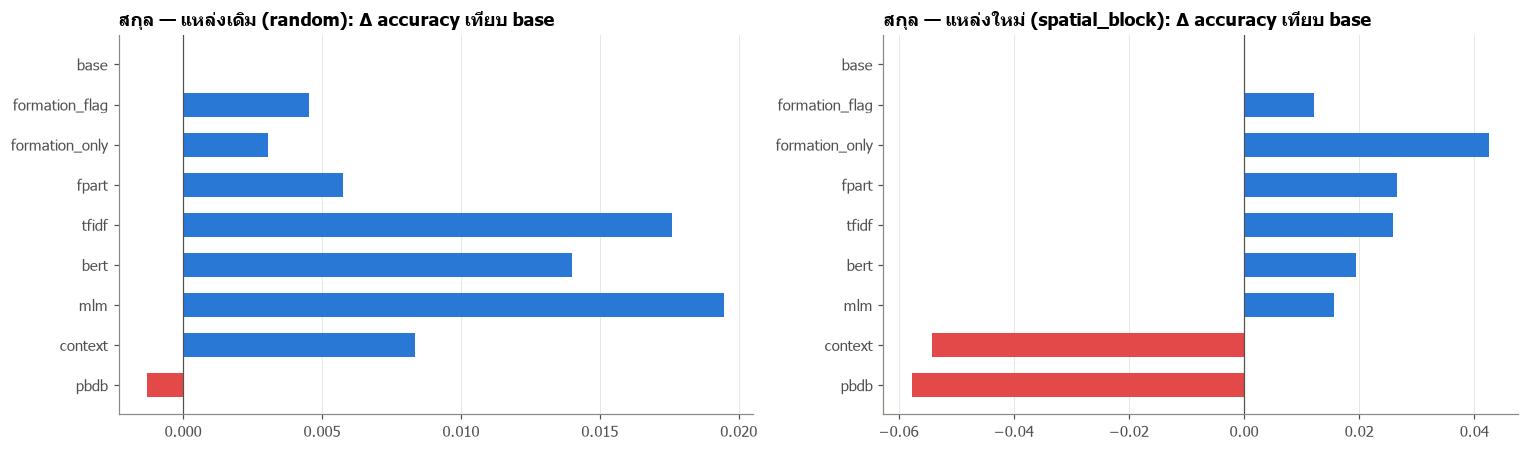

In [7]:
def eval_exp(reg, exp, cv, use_filter=True):
    o = reg.oof(exp)
    pc = [f"p_{j}" for j in range(len(GENERA))]
    labi = lab.set_index("fossil_id")
    acc, top3 = [], []
    for k, g in o.groupby("fold"):
        P = g[pc].values
        if use_filter:
            tr = labi[labi[f"fold_{cv}"] != k]
            P = ml.consistency_filter(P, GENERA, labi.loc[g.point_id, "groups"], ml.genus_group_map(tr.genus_cls, tr.groups))
        m = ml.multiclass_metrics(g.y.values, P, GENERA)
        acc.append(m["acc"]), top3.append(m["top3"])
    return np.mean(acc), np.mean(top3)


rows = []
for r, cv in ROUTES.items():
    for a in ADD:
        exp = f"{r}__{cv}__lgbm_fast@{a}"
        if len(regG.oof(exp) if regG.oof(exp) is not None else []) == 0:
            continue
        acc0, t30 = eval_exp(regG, exp, cv, False)
        acc1, t31 = eval_exp(regG, exp, cv, True)
        rows.append({"เส้นทาง": f"{r} ({cv})", "กลุ่มที่เพิ่ม": a, "acc": acc0, "top3": t30, "acc + ตัวกรอง": acc1, "top3 + ตัวกรอง": t31})
tS = pd.DataFrame(rows).set_index(["เส้นทาง", "กลุ่มที่เพิ่ม"])
base = tS.xs("base", level=1)
tS["Δacc + ตัวกรอง"] = [r["acc + ตัวกรอง"] - base.loc[i[0], "acc + ตัวกรอง"] for i, r in tS.iterrows()]
display(tS.style.format("{:.3f}").background_gradient(cmap="RdBu", subset=["Δacc + ตัวกรอง"], vmin=-0.05, vmax=0.05))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (r, cv) in zip(axes, ROUTES.items()):
    t = tS.xs(f"{r} ({cv})")
    ax.barh(t.index[::-1], t["Δacc + ตัวกรอง"][::-1], color=["#2a78d6" if v > 0 else "#e34948" for v in t["Δacc + ตัวกรอง"][::-1]], height=0.6)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(f"สกุล — {'แหล่งเดิม' if r == 'known' else 'แหล่งใหม่'} ({cv}): Δ accuracy เทียบ base")
    ax.grid(axis="y", visible=False)
plt.tight_layout()

## 4. ยุค: เพิ่มหมวดหิน / ธรณี+ / ผิวดิน

feature ฐาน = feature ของแหล่ง (notebook 11, LightGBM, train = ยุคที่บันทึก + ค่าเติมที่มี PBDB รองรับ) — วัดเฉพาะแหล่งที่ ทธ. บันทึกยุค
- `map_formation`: หมวดหินจาก**แผนที่ธรณี**ที่ตำแหน่งแหล่ง → ThaiLex (อายุ, ชนิดหิน) — มีทุกแหล่ง
- `recorded_formation`: `FORMATION` / `GEO_GROUP` ที่ ทธ. บันทึก (ตาราง notebook 07 แบบ Impute+Flag) + ThaiLex — วัด 2 แบบ: ตามที่บันทึก vs ซ่อนของแหล่งทดสอบ
- `+geo`, `+surface`: กลุ่ม `gx_`/`pgx_` และ `lc_` จาก notebook 13

In [8]:
fin = pd.read_csv(ml.DATA / "processed" / "sites_period_final.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
sites["period_rec"] = sites.oid.map({o: r[0] for o, r in rec.items()})
FILL_OK = fin.final_confidence.isin(["high", "medium"]) & fin.final_source.ne("DMR record") & fin.final_source.astype(str).str.contains("PBDB")
sites["period_train"] = sites.period_rec.fillna(sites.oid.map(fin[FILL_OK].set_index("OBJECTID").final_old))
PERIODS = [p for p in fl.PERIOD_ORDER if p in set(sites.period_train.dropna())]

leg = pd.read_csv(ml.DATA / "dmr_geology" / "rock_unit_250k_legend.csv", encoding="utf-8-sig").set_index("TEXT_SYM").label_th
mapfm = pd.DataFrame([thailex_feats(leg.get(s)) for s in sites.geo_rock_sym], index=sites.index).add_prefix("map_")
sf = pd.read_csv(ml.DATA / "processed" / "model" / "sites_impute_flag.csv", encoding="utf-8-sig")[["OBJECTID", "FORMATION", "GEO_GROUP", "formation_missing", "geo_group_missing"]]
sf = pd.concat([sf, pd.DataFrame([thailex_feats(n) for n in sf.FORMATION], index=sf.index).add_prefix("rec_")], axis=1)
sites = pd.concat([sites, mapfm], axis=1).merge(sf.rename(columns={"OBJECTID": "oid"}), on="oid", how="left")
has_fm = sites.formation_missing.eq(0)
print(f"แหล่งที่ ทธ. บันทึก FORMATION: ในแหล่งที่บันทึกยุค {has_fm[sites.period_rec.notna()].mean():.0%} | "
      f"ในแหล่งที่ต้องเติมยุค {has_fm[sites.period_rec.isna()].mean():.0%}")
sites = sites.merge(pd.read_parquet(ml.FEAT / "extra_features.parquet"), on="point_id", how="left")
for c in ["FORMATION", "GEO_GROUP"]:
    sites[c] = sites[c].astype(str)
grp = {g: [c for c in sites.columns if c.startswith(p)] for g, p in fl.EXTRA_GROUPS.items()}
SITE_BASE = (SITE_NUM + ["lon", "lat"], SITE_CAT)
ADDP = {"base": ([], []), "map_formation": ([c for c in mapfm.columns], []),
        "recorded_formation": ([c for c in sf.columns if c.startswith("rec_")] + ["formation_missing", "geo_group_missing"], ["FORMATION", "GEO_GROUP"]),
        "+geo": (grp["geo_plus"], []), "+surface": (grp["surface"], []),
        "map_formation+geo+surface": ([c for c in mapfm.columns] + grp["geo_plus"] + grp["surface"], [])}
dP = sites[sites.period_train.notna()].reset_index(drop=True)
yP = dP.period_train.map({p: i for i, p in enumerate(PERIODS)}).values
recorded_ids = set(sites.loc[sites.period_rec.notna(), "point_id"])
regP = ml.Registry(OUT / "period")
ml.set_multiclass(len(PERIODS))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=PERIODS, ordinal=fl.PERIOD_ORDER)
for cv in ml.tqdm_auto()(ml.CV_SCHEMES, desc="ยุค"):
    for a, (num, cat) in ADDP.items():
        ml.run_tabular_cv(regP, f"{cv}__lgbm@{a}", dP, yP, f"fold_{cv}", "lgbm", SITE_BASE[0] + num, SITE_BASE[1] + cat, task="multiclass", classes=PERIODS)


# ซ่อน FORMATION ของแหล่งทดสอบ (เหมือนตอนใช้จริงที่ 91% ไม่มีหมวดหิน): ใช้โมเดล fold เดิม ทำนายแถวทดสอบที่ตั้งค่าหมวดหินเป็นไม่ทราบ
def hidden_formation_acc(cv):
    num, cat = ADDP["recorded_formation"]
    accs = []
    for k in range(ml.N_FOLDS):
        te = dP[dP[f"fold_{cv}"].eq(k) & dP.point_id.isin(recorded_ids)].copy()
        te["FORMATION"], te["GEO_GROUP"], te["formation_missing"], te["geo_group_missing"] = "Unknown", "Unknown", 1, 1
        te[[c for c in num if c.startswith("rec_")]] = np.nan
        te["rec_fm_matched"] = 0
        P = ml.predict_bundle(regP.model_path(f"{cv}__lgbm@recorded_formation", k), te)
        accs.append((P.argmax(1) == te.period_train.map({p: i for i, p in enumerate(PERIODS)}).values).mean())
    return np.mean(accs)


def period_table():
    rows = []
    for cv in ml.CV_SCHEMES:
        for a in ADDP:
            o = regP.oof(f"{cv}__lgbm@{a}")
            o = o[o.point_id.isin(recorded_ids)]
            pc = [c for c in o.columns if c.startswith("p_")]
            m = [ml.multiclass_metrics(g.y.values, g[pc].values, PERIODS, fl.PERIOD_ORDER) for _, g in o.groupby("fold")]
            rows.append({"cv": cv, "กลุ่ม": a, "acc": np.mean([x["acc"] for x in m]), "within1": np.mean([x["within1"] for x in m])})
        rows.append({"cv": cv, "กลุ่ม": "recorded_formation (ซ่อนของแหล่งทดสอบ)", "acc": hidden_formation_acc(cv), "within1": np.nan})
    return pd.DataFrame(rows).pivot(index="กลุ่ม", columns="cv", values=["acc", "within1"])


tP = period_table()
display(tP.style.format("{:.3f}", na_rep="—").background_gradient(cmap="Blues", axis=None))

แหล่งที่ ทธ. บันทึก FORMATION: ในแหล่งที่บันทึกยุค 84% | ในแหล่งที่ต้องเติมยุค 9%


spatial_block__lgbm@map_formation+geo+surface:   0%|          | 0/5 [00:00<?, ?it/s]


## 5. ชุดรวมด้วยโมเดลเต็ม (ตกลงหลังคัดกรอง: แยกตามเส้นทาง)

- **แหล่งเดิม**: xgb + feature เดิม + TF-IDF (ดีขึ้นสม่ำเสมอสุดตอนคัดกรอง 5/5 fold)
- **แหล่งใหม่**: lgbm + feature เดิม + หมวดหิน (Impute only + ThaiLex) + ข้อความ — เทียบ WangchanBERTa กับ multilingual MiniLM
  (กติกาที่ตกลง: ลอง BERT ก่อน ถ้าไม่ดีกว่าใช้ multilingual) และแบบไม่มีข้อความ (ดูว่าข้อความช่วยจริงไหม)
- วัดเป็น**ระบบ** (สลับตามกรณี + ตัวกรองความสอดคล้อง) แบบ notebook 11 เทียบกับระบบฐานของ notebook 11 (registry `models/task1/genus_v5`) บน fold ชุดเดียวกัน
  — ใช้จริงถ้าดีกว่า (ตามที่ตกลง)

In [9]:
ADD["combo_known"] = (["@tfidf"], [])
ADD["combo_new_fm"] = FM_COLS["formation_only"]                                                   # หมวดหินอย่างเดียว (ablation)
ADD["combo_new"] = (FM_COLS["formation_only"][0] + ["@wangchanberta"], FM_COLS["formation_only"][1])
ADD["combo_new_mlm"] = (FM_COLS["formation_only"][0] + ["@multilingual"], FM_COLS["formation_only"][1])
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
for cv in ml.tqdm_auto()(["random", "spatial_block"], desc="ชุดรวม"):
    run_g(regG, "known", cv, "combo_known", model="xgb")
    for add in ["combo_new_fm", "combo_new", "combo_new_mlm"]:
        run_g(regG, "new", cv, add, model="lgbm")

REG_V3 = ml.Registry(ml.MODELS / "task1" / "genus_v5")      # ระบบปัจจุบันของ notebook 11 (label หลังตรวจทาน)
labi = lab.set_index("fossil_id")
assert (REG_V3.oof("random__xgb").set_index("point_id").fold.reindex(labi.index) == labi.fold_random).all(), "fold ไม่ตรงกับ notebook 11"


def routed_folds(cv, known, new):
    # known / new = (registry, exp): ระบบสลับตามกรณี + ตัวกรอง -> ต่อ fold: (fold, y จริง, ความน่าจะเป็น)
    a = known[0].oof(known[1]).set_index("point_id")
    b = new[0].oof(new[1]).set_index("point_id").loc[a.index]
    pc = [f"p_{j}" for j in range(len(GENERA))]
    for k in sorted(a.fold.unique()):
        ids = a.index[a.fold == k]
        tr = labi[labi[f"fold_{cv}"] != k]
        kn = ml.route_known_site(labi.loc[ids, "site_OBJECTID"], tr.site_OBJECTID.dropna().astype(int))
        P = np.where(kn[:, None], a.loc[ids, pc].values, b.loc[ids, pc].values)
        P = ml.consistency_filter(P, GENERA, labi.loc[ids, "groups"], ml.genus_group_map(tr.genus_cls, tr.groups))
        yield k, a.loc[ids, "y"].values, P


def routed(cv, known, new):
    # -> DataFrame (fold, acc, top3)
    rows = []
    for k, y, P in routed_folds(cv, known, new):
        m = ml.multiclass_metrics(y, P, GENERA)
        rows.append({"fold": k, "acc": m["acc"], "top3": m["top3"]})
    return pd.DataFrame(rows).set_index("fold")


SYSTEMS = {
    "ปัจจุบัน (notebook 11)": lambda cv: ((REG_V3, f"{cv}__xgb"), (REG_V3, f"{cv}__lgbm@specimen")),
    "แหล่งเดิม + TF-IDF": lambda cv: ((regG, f"known__{cv}__xgb@combo_known"), (REG_V3, f"{cv}__lgbm@specimen")),
    "แหล่งใหม่ + หมวดหิน": lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new_fm")),
    "แหล่งใหม่ + หมวดหิน + BERT": lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new")),
    "แหล่งใหม่ + หมวดหิน + multilingual": lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new_mlm")),
    "ชุดรวมทั้งสองเส้นทาง": lambda cv: ((regG, f"known__{cv}__xgb@combo_known"), (regG, f"new__{cv}__lgbm@combo_new")),
}
res = {(name, cv): routed(cv, *f(cv)) for name, f in SYSTEMS.items() for cv in ["random", "spatial_block"]}
rows = []
for (name, cv), r in res.items():
    base = res["ปัจจุบัน (notebook 11)", cv]
    d = r.acc - base.acc
    rows.append({"ระบบ": name, "cv": cv, "acc": r.acc.mean(), "top3": r.top3.mean(), "Δacc": d.mean(), "SD": d.std(), "ดีขึ้น (fold)": int((d > 0).sum())})
tC = pd.DataFrame(rows).set_index(["cv", "ระบบ"])
tC.reset_index().to_parquet(OUT / "genus_systems.parquet", index=False)        # ใช้ใน notebook 16 (เกณฑ์ความสำเร็จ)
COMBO_BETTER = {cv: tC.loc[(cv, "ชุดรวมทั้งสองเส้นทาง"), "Δacc"] > 0 for cv in ["random", "spatial_block"]}
display(tC.style.format({"acc": "{:.3f}", "top3": "{:.3f}", "Δacc": "{:+.4f}", "SD": "{:.4f}"}))
print("ชุดรวมดีกว่าระบบปัจจุบัน:", COMBO_BETTER)

new__spatial_block__lgbm@combo_new_mlm:   0%|          | 0/1 [00:00<?, ?it/s]


,,acc,top3,Δacc,SD,ดีขึ้น (fold)
cv,ระบบ,,,,,
random,ปัจจุบัน (notebook 11),0.656,0.859,+0.0000,0.0000,0
spatial_block,ปัจจุบัน (notebook 11),0.396,0.546,+0.0000,0.0000,0
random,แหล่งเดิม + TF-IDF,0.668,0.861,+0.0127,0.0087,5
spatial_block,แหล่งเดิม + TF-IDF,0.396,0.546,+0.0000,0.0000,0
random,แหล่งใหม่ + หมวดหิน,0.655,0.859,-0.0005,0.0007,0
spatial_block,แหล่งใหม่ + หมวดหิน,0.412,0.566,+0.0155,0.0637,3
random,แหล่งใหม่ + หมวดหิน + BERT,0.654,0.860,-0.0016,0.0036,2
spatial_block,แหล่งใหม่ + หมวดหิน + BERT,0.396,0.587,-0.0002,0.0703,2
random,แหล่งใหม่ + หมวดหิน + multilingual,0.655,0.860,-0.0005,0.0021,2


ชุดรวมดีกว่าระบบปัจจุบัน: {'random': np.True_, 'spatial_block': np.False_}


## 6. เส้นทาง "พิกัดใหม่": หมวดหินจากแผนที่ธรณีแทนที่ ทธ. บันทึก

ตัวอย่างจาก**พิกัดใหม่** (ไม่มีทะเบียนแหล่ง) ไม่มีหมวดหินที่ ทธ. บันทึก notebook 12 จึงใช้หมวดหินจากแผนที่ธรณี 1:250,000 ที่ตำแหน่งนั้น
ซึ่งไม่ใช่ข้อมูลแบบเดียวกับที่โมเดลเห็นตอน train — วัดระบบแหล่งใหม่ (`spatial_block`, ระบบเดียวกับหัวข้อ 5) โดยใช้โมเดลของ fold เดิม
แล้วเปลี่ยนแค่ข้อมูลหมวดหินของแถวทดสอบ: **บันทึก** = แบบหัวข้อ 5, **แผนที่** = หมวดหินจากแผนที่ที่ตำแหน่งแหล่ง (กลุ่มหิน = `Unknown`
แบบ notebook 12), **ไม่ใส่** = `Unknown` ทุกแถว

In [10]:
geo_sym = sites.set_index("oid").geo_rock_sym.astype(str)
FM_ALL = FM_COLS["formation_only"][0] + FM_COLS["formation_only"][1]
rec_fm = lab["fm_FORMATION__formation_only"].tolist()
map_fm = [fl.map_formation_name(geo_sym.get(int(s), "nan")) if pd.notna(s) else "Unknown" for s in lab.site_OBJECTID]


def fm_variant(names, groups):
    # ตาราง fm_* แบบเดียวกับที่ notebook 11/12 สร้าง (feature_lib.formation_features) สำหรับชื่อหมวดหินชุดใหม่
    f = fl.formation_features(names).add_suffix("__formation_only")
    f["fm_FORMATION__formation_only"], f["fm_GEO_GROUP__formation_only"] = [str(n) for n in names], [str(g) for g in groups]
    return f.reindex(columns=FM_ALL)


chk = fm_variant(rec_fm, lab["fm_GEO_GROUP__formation_only"])                 # ตรวจ: สร้างแบบ "บันทึก" ใหม่ต้องได้ค่าเดียวกับที่ใช้ train
assert np.allclose(chk[FM_COLS["formation_only"][0]].astype(float).values, lab[FM_COLS["formation_only"][0]].astype(float).values, equal_nan=True)
FM_VARIANTS = {"บันทึก (หัวข้อ 5)": chk, "แผนที่ (พิกัดใหม่)": fm_variant(map_fm, ["Unknown"] * len(lab)),
               "ไม่ใส่": fm_variant(["Unknown"] * len(lab), ["Unknown"] * len(lab))}
has_rec = lab["fm_FORMATION__formation_only"].ne("Unknown").values
print(f"ตัวอย่างที่ ทธ. บันทึกหมวดหิน {has_rec.mean():.0%} | ในกลุ่มนี้ชื่อจากแผนที่ตรงกับที่บันทึก "
      f"{np.mean(np.array(map_fm)[has_rec] == np.array(rec_fm)[has_rec]):.0%}, แผนที่ไม่มีชื่อหมวดหิน {np.mean(np.array(map_fm)[has_rec] == 'Unknown'):.0%}")

num_new = NEW_BASE[0] + ADD["combo_new"][0]
known_oof = regG.oof("known__spatial_block__xgb@combo_known").set_index("point_id")
pc = [f"p_{j}" for j in range(len(GENERA))]
rows = []
for name, V in FM_VARIANTS.items():
    d = lab.copy()
    for c in FM_ALL:
        d[c] = V[c].values
    for k in range(ml.N_FOLDS):
        dk, _ = fold_frame(d, "spatial_block", k, num_new)
        te = dk.fold_spatial_block.values == k
        ids = dk.fossil_id.values[te]
        tr = labi[labi.fold_spatial_block != k]
        kn = ml.route_known_site(labi.loc[ids, "site_OBJECTID"], tr.site_OBJECTID.dropna().astype(int))
        P = np.where(kn[:, None], known_oof.loc[ids, pc].values,
                     ml.predict_bundle(regG.model_path("new__spatial_block__lgbm@combo_new", k), dk[te]))
        P = ml.consistency_filter(P, GENERA, labi.loc[ids, "groups"], ml.genus_group_map(tr.genus_cls, tr.groups))
        y = known_oof.loc[ids, "y"].values
        for part, msk in [("ทั้งหมด", np.ones(len(ids), bool)), ("แหล่งที่บันทึกหมวดหิน", has_rec[te])]:
            m = ml.multiclass_metrics(y[msk], P[msk], GENERA)
            rows.append({"หมวดหินที่ป้อน": name, "แถวทดสอบ": part, "fold": k, "n": int(msk.sum()), "acc": m["acc"], "top3": m["top3"]})
tM = (pd.DataFrame(rows).groupby(["แถวทดสอบ", "หมวดหินที่ป้อน"], sort=False)
      .agg(n=("n", "sum"), acc=("acc", "mean"), top3=("top3", "mean")))
display(tM.style.format({"acc": "{:.3f}", "top3": "{:.3f}"}))
ref = tC.loc[("spatial_block", "ชุดรวมทั้งสองเส้นทาง")]
assert np.isclose(tM.loc[("ทั้งหมด", "บันทึก (หัวข้อ 5)"), "acc"], ref.acc) and np.isclose(tM.loc[("ทั้งหมด", "บันทึก (หัวข้อ 5)"), "top3"], ref.top3), \
    "แบบ 'บันทึก' ต้องได้เท่ากับระบบในหัวข้อ 5"
print("ตรวจ: แบบ 'บันทึก' ได้ค่าเท่ากับหัวข้อ 5 ✓")

ตัวอย่างที่ ทธ. บันทึกหมวดหิน 29% | ในกลุ่มนี้ชื่อจากแผนที่ตรงกับที่บันทึก 19%, แผนที่ไม่มีชื่อหมวดหิน 8%


,,n,acc,top3
แถวทดสอบ,หมวดหินที่ป้อน,,,
ทั้งหมด,บันทึก (หัวข้อ 5),3944,0.396,0.587
แหล่งที่บันทึกหมวดหิน,บันทึก (หัวข้อ 5),1149,0.289,0.588
ทั้งหมด,แผนที่ (พิกัดใหม่),3944,0.396,0.584
แหล่งที่บันทึกหมวดหิน,แผนที่ (พิกัดใหม่),1149,0.278,0.579
ทั้งหมด,ไม่ใส่,3944,0.377,0.570
แหล่งที่บันทึกหมวดหิน,ไม่ใส่,1149,0.248,0.557


ตรวจ: แบบ 'บันทึก' ได้ค่าเท่ากับหัวข้อ 5 ✓


## 7. ทายสกุลเมื่อไม่รู้ประเภทซาก (เว็บ: "ซากที่พบหน้าตาเป็นอย่างไร")

คนทั่วไปมักไม่รู้ประเภทซาก (`f_type`) ซึ่งเป็นข้อมูลหลักของโมเดลสกุล เว็บจึงถามหน้าตาแทน (การ์ดรูป → คำถามต่อเฉพาะที่กำกวม;
`feature_lib.APPEARANCE`) แล้วให้น้ำหนักแต่ละประเภทจาก**จำนวนตัวอย่างในทะเบียน**ที่เป็นประเภทนั้นและมีส่วนของซากตรงคำตอบ
(ตัดหาง: สะสม 97% ไม่เกิน 5 ประเภท) → รันโมเดลสกุลทีละประเภท แล้วรวม P(สกุล) ตามน้ำหนัก

วัดระบบที่ใช้จริง (หัวข้อ 5 "ชุดรวม") ด้วย**โมเดลของ fold เดิม** แล้วเปลี่ยนเฉพาะข้อมูลตัวอย่างของแถวทดสอบ
(น้ำหนักประเภท / คำบรรยายส่วนของซากคำนวณจากตัวอย่างที่ไม่อยู่ใน fold ทดสอบเท่านั้น; ข้อความ fit กับแถว train แบบเดิม):

| แบบ | ข้อมูลตัวอย่างที่ป้อน |
|---|---|
| ทะเบียนจริง | ค่าตามทะเบียน (= หัวข้อ 5; ใช้ตรวจว่าสร้าง feature ใหม่ได้ตรง) |
| รู้ประเภท ไม่มีชื่อเรียก | ประเภทจริง แต่ไม่มีชื่อที่ผู้บันทึกเรียก และส่วนของซากใช้คำที่ทะเบียนเขียนบ่อยสุด (= ทางลัด "เลือกประเภทเอง" ของเว็บ) |
| บอกหน้าตา ตอบคำถามต่อ | การ์ด + คำถามต่อที่เข้ากับซากจริง (ถ้าเข้าได้หลายข้อใช้ข้อที่เจาะจงสุด) |
| บอกหน้าตา แค่รูปแรก | การ์ดเดียวกัน แต่ตอบคำถามต่อว่า "ไม่แน่ใจ" |

แบบบอกหน้าตาวัดตามที่เว็บแสดง: **"อื่น ๆ" แยกตามกลุ่มซาก** (กลุ่มเดียวกับตัวกรองความสอดคล้อง เช่น ไดโนเสาร์ = ไดโนเสาร์ + ซอโรพอด;
น้ำหนักประเภท × P("อื่น ๆ" | ประเภท) รวมในกลุ่ม เป็นรายการของตัวเอง เช่น "ไดโนเสาร์ที่ยังระบุชื่อไม่ได้") และนับว่าถูกเมื่อรายการ "อื่น ๆ"
ของ**กลุ่มจริง**อยู่ในอันดับ (ค่าเท่ากันนับแบบระวัง) — ถ้ารวมเป็นรายการเดียว "อื่น ๆ"
จะสะสมคะแนนจากทุกประเภทจนขึ้นอันดับ 1 ทั้งที่บอกไม่ได้ว่าเป็นกลุ่มไหน

In [11]:
# ---- จำลองผู้ใช้ที่ไม่รู้ประเภทซาก แล้ววัดระบบจริงด้วยโมเดลของ fold เดิม
SCEN = {"base": "ทะเบียนจริง", "type_nocom": "รู้ประเภท ไม่มีชื่อเรียก", "look_full": "บอกหน้าตา ตอบคำถามต่อ", "look_card": "บอกหน้าตา แค่รูปแรก",
        "look_unknown": "เลือก \"ไม่ตรงกับแบบไหน\""}
SCEN.update({f"{k}_noloc": f"{v} · ไม่บอกที่พบ" for k, v in list(SCEN.items())})   # ไม่มีจังหวัด / อำเภอ / แหล่ง / หมวดหิน (เว็บ: ที่พบ "ไม่ทราบ")
DEP = fl.APPEARANCE_PART_POLICY
POLICIES = {"mode": "คำที่ทะเบียนเขียนบ่อยสุด", "generic": "คำกลางของการ์ด", "blank": "ไม่ใส่"}     # วิธีเติม "ส่วนของซาก"
ROUTE_EXP = {"known": ("known__{cv}__xgb@combo_known", KNOWN_BASE, "combo_known"), "new": ("new__{cv}__lgbm@combo_new", NEW_BASE, "combo_new")}
pc = [f"p_{j}" for j in range(len(GENERA))]
gidx = {g: i for i, g in enumerate(GENERA)}


def look_variants(te, spec_tr):
    # แถวทดสอบ -> แถวที่ป้อนโมเดล: (แบบ, วิธีเติมส่วนของซาก, ตัวอย่าง, น้ำหนักประเภท, ประเภท / กลุ่ม / ส่วนของซาก / ชื่อเรียก ที่ป้อน)
    LT = fl.appearance_leaf_types(spec_tr)
    TG = spec_tr.dropna(subset=["f_type", "f_group"]).groupby("f_type").f_group.agg(lambda s: s.value_counts().idxmax())
    W, PART = {}, {}
    weights = lambda leaf: W.setdefault(leaf, fl.appearance_type_weights(leaf, spec_tr, leaf_types=LT))
    part = lambda t, leaf, pol: PART.setdefault((t, leaf, pol), fl.appearance_part(t, leaf, spec_tr, policy=pol))
    rows = []
    for r in te.itertuples():
        full, card = fl.appearance_truth(r.f_type, None if r.f_part == "nan" else r.f_part, spec_tr, LT)
        for sfx in ["", "_noloc"]:
            rows.append(dict(scen="base" + sfx, pol="-", fid=r.fossil_id, w=1.0, f_type=r.f_type, f_group=r.f_group, f_part=r.f_part,
                             com=r.com_name_generic, leaf=full))
        for pol in POLICIES:
            # วิธีเติมทุกแบบวัดเฉพาะกรณีบอกที่พบ (ใช้เลือกวิธี); กรณีไม่บอกที่พบ / เลือก "ไม่ตรงกับแบบไหน" วัดเฉพาะวิธีที่ใช้จริง
            todo = [("type_nocom", None), ("look_full", full), ("look_card", card)]
            if pol == DEP:
                todo += [("type_nocom_noloc", None), ("look_full_noloc", full), ("look_card_noloc", card),
                         ("look_unknown", "unknown"), ("look_unknown_noloc", "unknown")]
            for scen, leaf in todo:
                if leaf is None:
                    rows.append(dict(scen=scen, pol=pol, fid=r.fossil_id, w=1.0, f_type=r.f_type, f_group=r.f_group, f_part=part(r.f_type, full, pol),
                                     com=r.f_type, leaf=full))
                    continue
                Wl = weights(leaf)
                for t, w in Wl.items():
                    rows.append(dict(scen=scen, pol=pol, fid=r.fossil_id, w=float(w), f_type=t, f_group=str(TG.get(t, "nan")), f_part=part(t, leaf, pol),
                                     com=t, leaf=full, true_w=float(Wl.get(r.f_type, 0.0)), top_type=Wl.index[0]))
    return pd.DataFrame(rows)


NO_FM = FM_VARIANTS["ไม่ใส่"].iloc[0]                          # หมวดหิน "Unknown" แบบเดียวกับหัวข้อ 6


res_rows, card_rows, chk = [], [], []
for cv in ["random", "spatial_block"]:
    for k in ml.tqdm_auto()(range(ml.N_FOLDS), desc=f"หน้าตา {cv}"):
        te = lab[lab[f"fold_{cv}"] == k]
        spec_tr = S.loc[~S.fossil_id.isin(te.fossil_id), ["f_type", "f_part", "f_group"]].replace("nan", np.nan)
        V = look_variants(te, spec_tr)
        X = te.set_index("fossil_id").loc[V.fid].reset_index()
        X["f_type"], X["f_group"], X["com_name_generic"] = V.f_type.values, V.f_group.astype(str).values, V.com.values
        X["f_part"] = V.f_part.fillna("nan").astype(str).values
        X["groups"] = [fl.specimen_classes(t, c) for t, c in zip(X.f_type, X.com_name_generic)]
        nl = V.scen.str.endswith("_noloc").values                  # ไม่บอกที่พบ: ไม่มีจังหวัด / อำเภอ / แหล่ง (จึงไปเส้นทางแหล่งใหม่) / หมวดหิน
        X.loc[nl, ["province", "district"]] = "nan"
        X.loc[nl, "site_OBJECTID"] = pd.NA
        for c in FM_ALL:
            X.loc[nl, c] = NO_FM[c]
        d_ext = pd.concat([lab, X], ignore_index=True)            # แถวที่เพิ่มอยู่ fold k จึงไม่ถูกใช้ fit ตัวแปลงข้อความ
        tr = labi[labi[f"fold_{cv}"] != k]
        kn = ml.route_known_site(X.site_OBJECTID, tr.site_OBJECTID.dropna().astype(int))
        P = {}
        for route, (exp, base, add) in ROUTE_EXP.items():
            dk, _ = fold_frame(d_ext, cv, k, base[0] + ADD[add][0])
            P[route] = ml.predict_bundle(regG.model_path(exp.format(cv=cv), k), dk.iloc[len(lab):].reset_index(drop=True))
            o = regG.oof(exp.format(cv=cv)).set_index("point_id")       # ตรวจ: แบบทะเบียนจริงต้องได้ค่าเดิมของหัวข้อ 5
            b = (V.scen == "base").values
            chk.append(float(np.abs(P[route][b] - o.loc[V.fid[b], pc].values).max()))
        PV = np.where(kn[:, None], P["known"], P["new"])
        PV = ml.consistency_filter(PV, GENERA, X.groups, ml.genus_group_map(tr.genus_cls, tr.groups))
        y_of = dict(zip(te.fossil_id, te.genus_cls.map(gidx)))
        t_of = {f: fl.other_group(t) for f, t in zip(te.fossil_id, te.f_type)}
        OTH = gidx["อื่น ๆ"]
        for (scen, pol), idx in V.groupby(["scen", "pol"], sort=False).groups.items():
            m = np.zeros(len(V), bool)
            m[V.index.get_indexer(idx)] = True
            W = PV[m] * V.w.values[m, None]
            Pm = pd.DataFrame(W, index=V.fid.values[m]).groupby(level=0, sort=False).sum()
            y = Pm.index.map(y_of).values
            one = V[m].drop_duplicates("fid").set_index("fid").loc[Pm.index]
            if scen.startswith("look"):
                # แบบที่เว็บแสดง: "อื่น ๆ" แยกตามกลุ่มซาก (fl.other_group) — นับถูกเมื่อ "อื่น ๆ" ของกลุ่มจริงอยู่ในอันดับ;
                # ค่าเท่ากันนับแบบระวัง (ทุกรายการที่ ≥ ค่าของคำตอบอยู่ก่อน) และคำตอบที่ความน่าจะเป็น 0 ไม่นับว่าถูก
                Pn = Pm.copy()
                Pn[OTH] = 0.0
                oth = pd.DataFrame({"fid": V.fid.values[m], "t": [fl.other_group(t) for t in V.f_type.values[m]], "p": W[:, OTH]}
                                   ).groupby(["fid", "t"], sort=False).p.sum()
                rank = []
                for fid, row_p, yy in zip(Pn.index, Pn.values, y):
                    o = oth.loc[fid]
                    s_true = o.get(t_of[fid], 0.0) if yy == OTH else row_p[yy]
                    rank.append(10 ** 6 if s_true <= 0 else int((row_p >= s_true).sum() + (o.values >= s_true).sum()) - 1)
                rank = np.array(rank)
                met = {"acc": float(np.mean(rank == 0)), "top3": float(np.mean(rank < 3))}
                hit = rank < 3
                # เทียบ: "อื่น ๆ" รวมเป็นรายการเดียว (ก่อนแยกตามกลุ่ม) นับอันดับแบบระวังเหมือนกัน
                s_m = Pm.values[np.arange(len(y)), y]
                rank_m = np.where(s_m > 0, (Pm.values >= s_m[:, None]).sum(axis=1) - 1, 10 ** 6)
                met.update(acc_merged=float(np.mean(rank_m == 0)), top3_merged=float(np.mean(rank_m < 3)))
            else:
                met = ml.multiclass_metrics(y, Pm.values, GENERA)
                met.update(acc_merged=met["acc"], top3_merged=met["top3"])
                hit = np.array([yy in np.argsort(-pp)[:3] for yy, pp in zip(y, Pm.values)])
            row = {"cv": cv, "fold": k, "scenario": scen, "policy": pol, "n": len(Pm), "acc": met["acc"], "top3": met["top3"],
                   "acc_merged": met["acc_merged"], "top3_merged": met["top3_merged"]}
            if scen.startswith("look"):
                row.update(type_top1=float((one.top_type == te.set_index("fossil_id").loc[Pm.index, "f_type"]).mean()),
                           type_kept=float((one.true_w > 0).mean()), oth_top1=float(np.mean(Pn.values.max(axis=1) < oth.groupby(level=0, sort=False).max().loc[Pn.index].values)))
            else:
                row.update(oth_top1=float(np.mean(Pm.values.argmax(axis=1) == OTH)))
            res_rows.append(row)
            cards = one.leaf.str.split("/").str[0].values
            card_rows += [{"cv": cv, "fold": k, "scenario": scen, "policy": pol, "card": c, "n": int((cards == c).sum()),
                           "hits": int(hit[cards == c].sum())} for c in np.unique(cards)]

print(f"ตรวจ: แบบทะเบียนจริงสร้าง feature ใหม่แล้วได้ความน่าจะเป็นเดิม (ต่างสูงสุด {max(chk):.2g})")
assert max(chk) < 1e-5, "สร้าง feature ใหม่ไม่ตรงกับที่ใช้ train"
R = pd.DataFrame(res_rows)
tL = R.groupby(["cv", "scenario", "policy"], sort=False).agg(n=("n", "sum"), acc=("acc", "mean"), top3=("top3", "mean"),
                                                            acc_merged=("acc_merged", "mean"), top3_merged=("top3_merged", "mean"),
                                                            type_top1=("type_top1", "mean"), type_kept=("type_kept", "mean"),
                                                            oth_top1=("oth_top1", "mean")).reset_index()
for cv in ["random", "spatial_block"]:
    ref, b = tC.loc[(cv, "ชุดรวมทั้งสองเส้นทาง")], tL[(tL.cv == cv) & (tL.scenario == "base")].iloc[0]
    assert np.isclose(b.acc, ref.acc) and np.isclose(b.top3, ref.top3), "แบบทะเบียนจริงต้องเท่าหัวข้อ 5"
print("ตรวจ: แบบทะเบียนจริงได้ acc / top-3 เท่าหัวข้อ 5 ✓")

# วิธีเติมส่วนของซาก: เลือกด้วย top-3 เฉลี่ยของ "บอกหน้าตา ตอบคำถามต่อ" ทั้งสองแบบ CV
pol_score = tL[tL.scenario == "look_full"].groupby("policy").top3.mean()
BEST_POLICY = pol_score.idxmax()
print("top-3 เฉลี่ย (บอกหน้าตา ตอบคำถามต่อ) ตามวิธีเติมส่วนของซาก:", pol_score.round(3).to_dict(), "-> ดีสุด:", BEST_POLICY,
      "| ที่ใช้จริง (feature_lib.APPEARANCE_PART_POLICY):", fl.APPEARANCE_PART_POLICY)
tL["deployed"] = tL.policy.isin(["-", fl.APPEARANCE_PART_POLICY])
tL["best_policy"] = BEST_POLICY
tL = tL.assign(scenario_th=lambda d: d.scenario.map(SCEN))
tL.to_parquet(OUT / "appearance_eval.parquet", index=False)         # ใช้ใน notebook 16 / README / เว็บ (ความแม่นที่บอกผู้ใช้)
show = tL.assign(แบบ=lambda d: d.scenario_th + np.where(d.policy == "-", "", " · " + d.policy.map(POLICIES)))
display(show.pivot(index="แบบ", columns="cv", values=["acc", "top3"]).style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))
display(tL[tL.scenario.str.startswith("look") & tL.deployed].set_index(["cv", "scenario_th"])[["type_top1", "type_kept"]]
        .rename(columns={"type_top1": "ประเภทน้ำหนักสูงสุด = ประเภทจริง", "type_kept": "ประเภทจริงอยู่ในชุดที่รวม"}).style.format("{:.1%}"))
# ผลของการแยก "อื่น ๆ" ตามกลุ่ม (แบบที่เว็บแสดง) เทียบรวมเป็นรายการเดียว — top-3 ของวิธีที่ใช้จริง
LOOK = [s for s in SCEN if s.startswith("look")]
display(tL[tL.deployed & tL.scenario.isin(LOOK)].set_index(["cv", "scenario_th"])[["top3_merged", "top3"]]
        .rename(columns={"top3_merged": "top-3 รวม \"อื่น ๆ\" เป็นรายการเดียว", "top3": "top-3 แยกตามกลุ่ม (เว็บ)"}).style.format("{:.3f}"))
display(tL[tL.deployed].pivot(index="scenario_th", columns="cv", values="oth_top1").reindex(list(SCEN.values()))
        .rename_axis("สัดส่วนที่ \"ยังระบุชื่อไม่ได้\" ขึ้นอันดับ 1").style.format("{:.1%}"))
C = pd.DataFrame(card_rows)
C = C[C.policy.isin(["-", fl.APPEARANCE_PART_POLICY])].groupby(["card", "scenario", "cv"]).agg(n=("n", "sum"), hits=("hits", "sum"))
C = C.assign(top3=C.hits / C.n).reset_index()
C.to_parquet(OUT / "appearance_eval_cards.parquet", index=False)
tCard = C.pivot_table(index="card", columns=["cv", "scenario"], values="top3").reindex(columns=list(SCEN), level=1)
n_card = C[C.scenario.eq("base") & C.cv.eq("random")].set_index("card").n
display(tCard.loc[n_card.sort_values(ascending=False).index].rename(index=lambda c: f"{c} (n={n_card[c]})").style.format("{:.3f}"))

หน้าตา spatial_block: 100%|██████████| 5/5 [01:56<00:00, 23.25s/it]


ตรวจ: แบบทะเบียนจริงสร้าง feature ใหม่แล้วได้ความน่าจะเป็นเดิม (ต่างสูงสุด 0)
ตรวจ: แบบทะเบียนจริงได้ acc / top-3 เท่าหัวข้อ 5 ✓
top-3 เฉลี่ย (บอกหน้าตา ตอบคำถามต่อ) ตามวิธีเติมส่วนของซาก: {'blank': 0.502, 'generic': 0.598, 'mode': 0.556} -> ดีสุด: generic | ที่ใช้จริง (feature_lib.APPEARANCE_PART_POLICY): generic


cv,random,spatial_block
"สัดส่วนที่ ""ยังระบุชื่อไม่ได้"" ขึ้นอันดับ 1",,
ทะเบียนจริง,15.3%,13.3%
รู้ประเภท ไม่มีชื่อเรียก,24.1%,33.8%
บอกหน้าตา ตอบคำถามต่อ,25.0%,36.2%
บอกหน้าตา แค่รูปแรก,32.9%,45.2%
"เลือก ""ไม่ตรงกับแบบไหน""",12.7%,0.2%
ทะเบียนจริง · ไม่บอกที่พบ,5.8%,11.6%
รู้ประเภท ไม่มีชื่อเรียก · ไม่บอกที่พบ,31.1%,31.8%
บอกหน้าตา ตอบคำถามต่อ · ไม่บอกที่พบ,31.6%,31.8%
บอกหน้าตา แค่รูปแรก · ไม่บอกที่พบ,23.7%,28.7%


## 8. Confusion matrix ของระบบที่ใช้จริง

ผลทำนายนอก fold ของระบบที่ใช้จริง รวมทุก fold — **แถว = คำตอบจริง, คอลัมน์ = คำตอบอันดับ 1 ของระบบ**, สีและตัวเลขในช่อง = ร้อยละของแถว
(แนวทแยง = ทายถูก), ตัวเลขในวงเล็บหลังชื่อแถว = จำนวนจริง
- **สกุล (`SCI_NAME`)**: ระบบสลับตามกรณี + ตัวกรองความสอดคล้อง (ชุดรวมทั้งสองเส้นทาง = `genus_v7`) ทั้งแหล่งเดิม (`random`) และแหล่งใหม่ (`spatial_block`)
  — 132 คลาสอ่านไม่ได้ในภาพเดียว จึงแสดง 25 สกุลที่มีตัวอย่างมากสุด + "อื่น ๆ" และรวมสกุลที่เหลือเป็นแถว / คอลัมน์เดียว
  (ตารางเต็ม 132 × 132 และ precision / recall รายสกุลบันทึกเป็น CSV)
- **ยุค (`PERIODFROM`)**: LightGBM `+surface` (train ด้วยยุคที่บันทึก + ค่าเติมที่มี PBDB รองรับ) วัดบนแหล่งที่ ทธ. บันทึกยุค เรียงตามเวลาธรณี
  — ช่องที่ติดแนวทแยงคือทายผิดไปยุคข้างเคียง (นับเป็นถูกใน within-1)
- accuracy จาก confusion matrix รวมทุก fold จึงต่างจากค่าเฉลี่ยต่อ fold ในหัวข้อ 4–5 เล็กน้อย
- ภาพบันทึกที่ `docs/figures/`, CSV ที่ `models/task1/FE/confusion/`

,ตัวอย่าง,accuracy รวมทุก fold,accuracy เฉลี่ยต่อ fold (หัวข้อ 5)
cv,,,
random,"3,944",0.667,0.667
spatial_block,"3,944",0.382,0.396


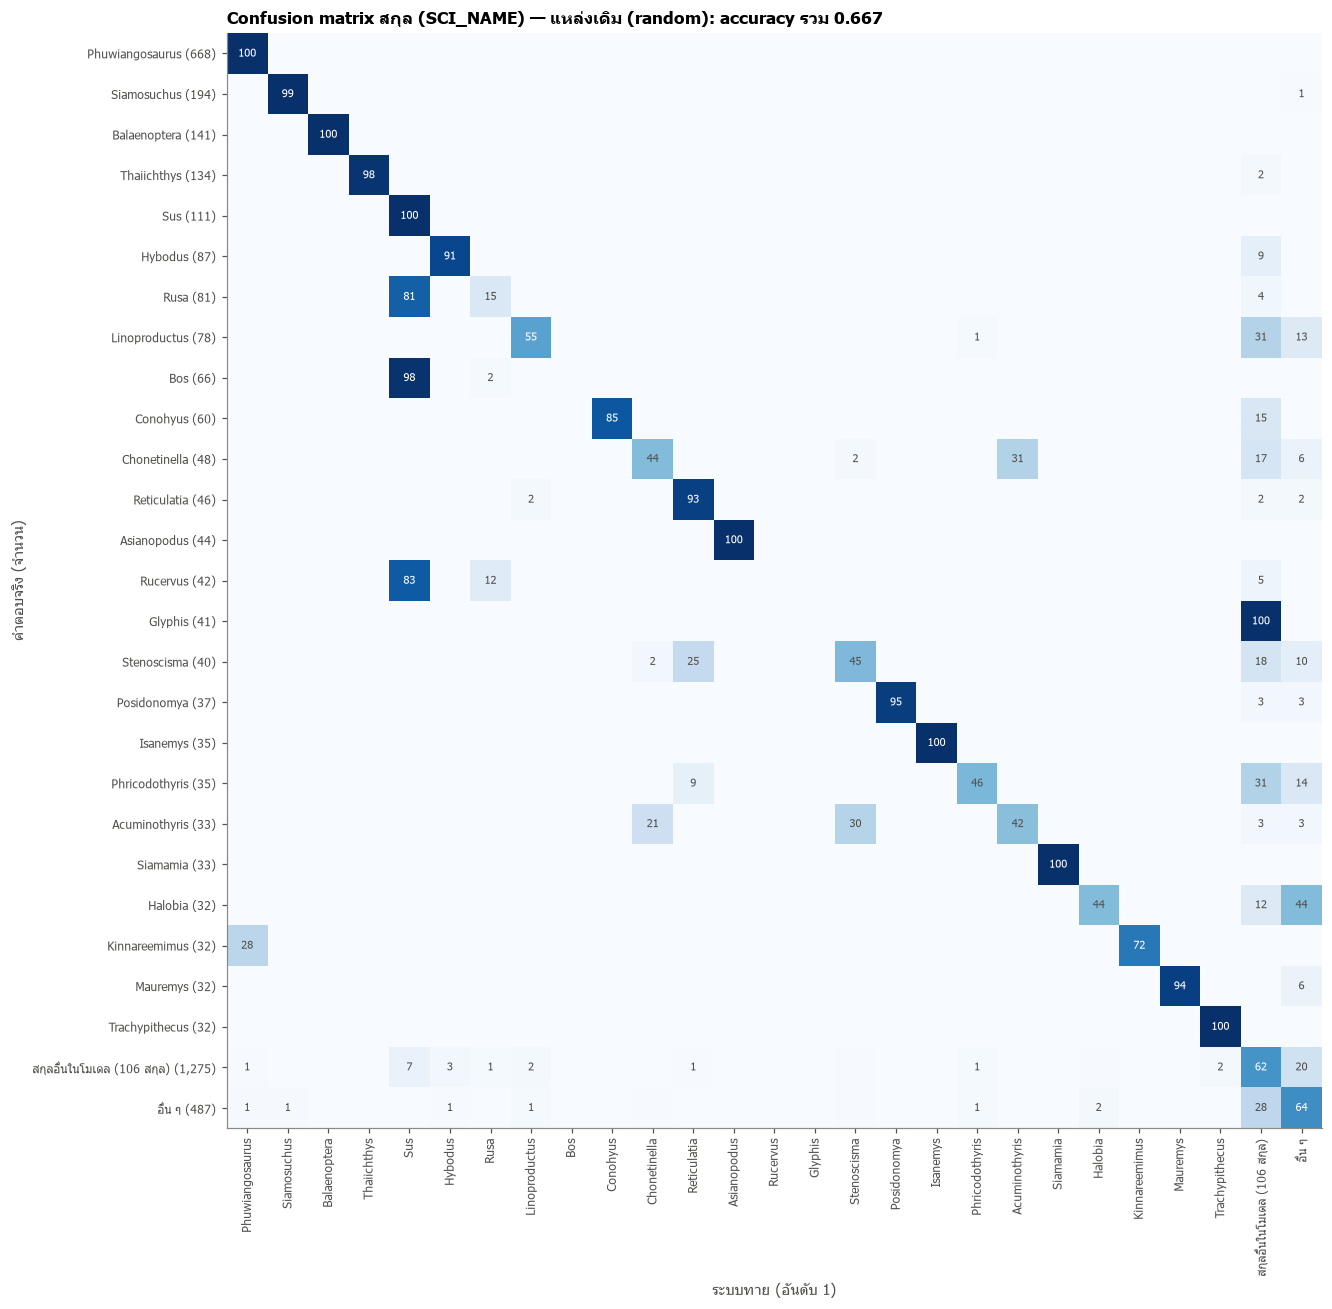

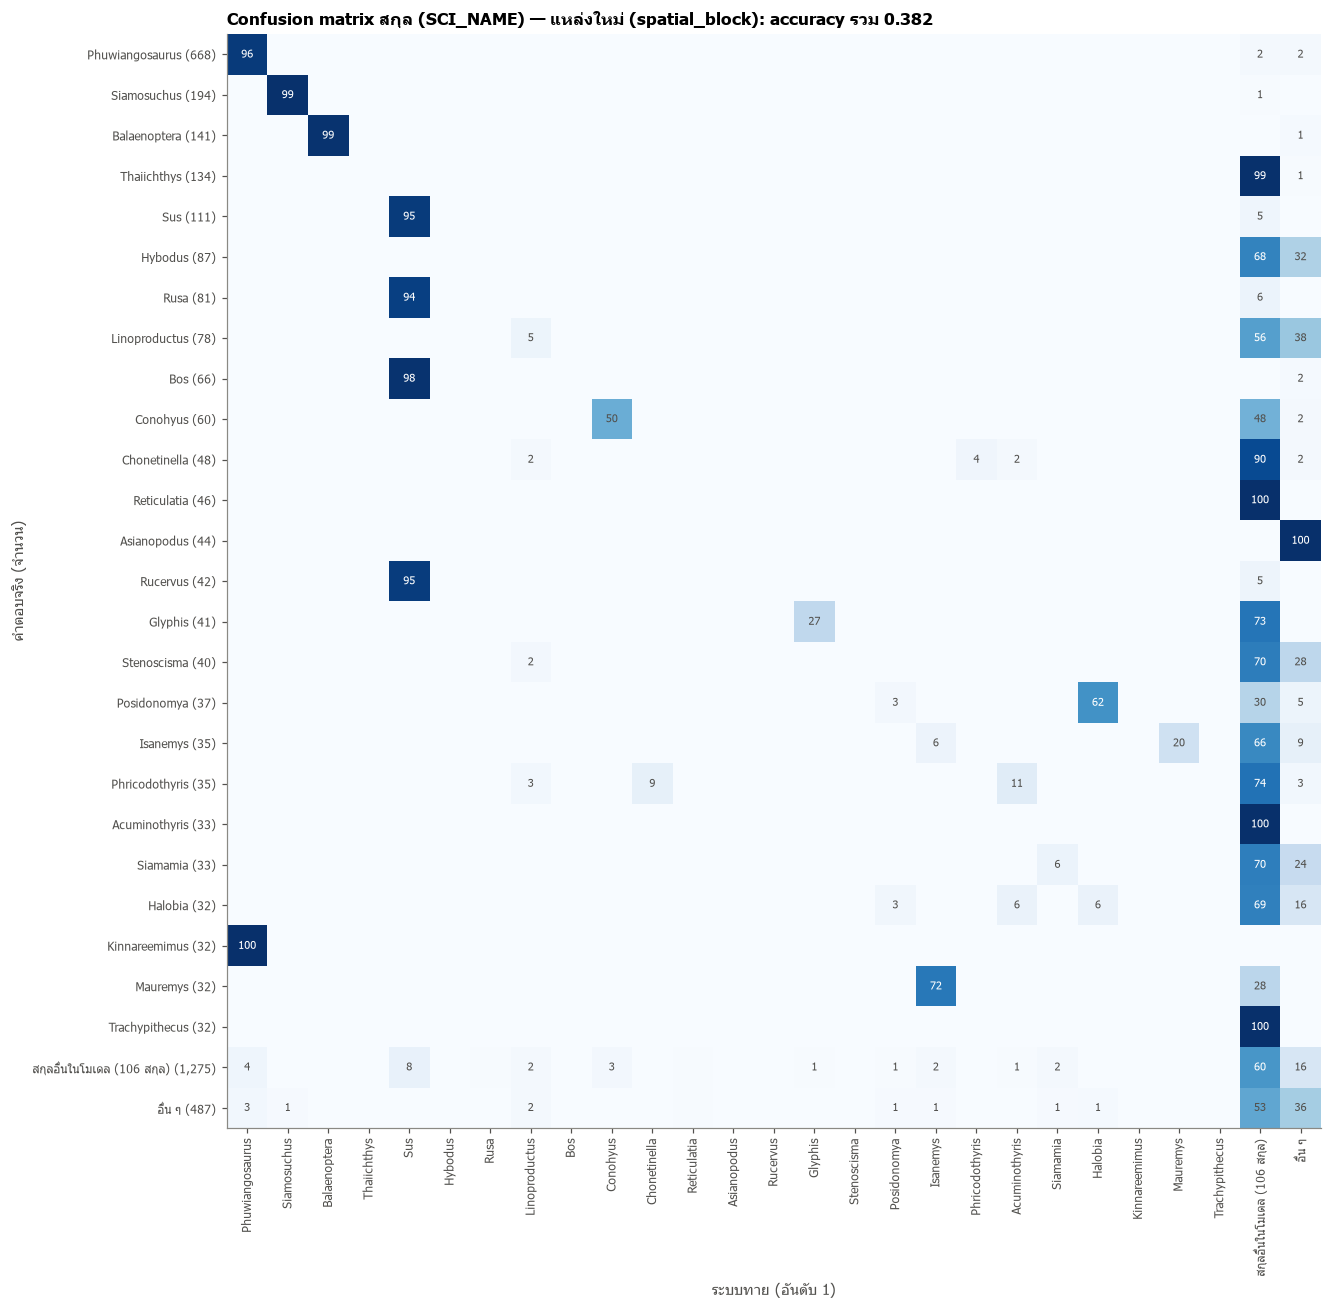

[แหล่งเดิม (random)] คู่ที่ทายผิดบ่อยสุด: Rusa → Sus 66; Bos → Sus 65; Rucervus → Sus 35; Glyphis → Galeocerdo 24; Capricornis → Sus 24; Muntiacus → Sus 23; Heteroptychodus → Hybodus 22; Pongo → Trachypithecus 19; Bubalus → Sus 18; Glyphis → Carcharhinus 17
[แหล่งใหม่ (spatial_block)] คู่ที่ทายผิดบ่อยสุด: Thaiichthys → Eubiodectes 127; Rusa → Sus 76; Bos → Sus 65; Hybodus → Thaiodus 56; Reticulatia → Schizophoria 45; Asianopodus → อื่น ๆ 44; Rucervus → Sus 40; Chonetinella → Schizophoria 34; Trachypithecus → Khoratpithecus 32; Kinnareemimus → Phuwiangosaurus 32


In [12]:
from sklearn.metrics import confusion_matrix

FIG_DIR, CM_DIR = ml.ROOT / "docs" / "figures", OUT / "confusion"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CM_DIR.mkdir(parents=True, exist_ok=True)
CV_TH = {"random": "แหล่งเดิม (random)", "spatial_block": "แหล่งใหม่ (spatial_block)"}


def plot_cm(ax, cm, labels, title, fs=7, annot_min=0.5):
    # สี = ร้อยละของแถว; ตัวเลขในช่อง = ร้อยละ (แสดงเมื่อ ≥ annot_min)
    n = cm.sum(1, keepdims=True)
    pct = np.divide(cm, n, out=np.zeros(cm.shape), where=n > 0) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i, j in zip(*np.nonzero(cm)):
        if pct[i, j] >= annot_min:
            ax.text(j, i, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=fs - 0.5, color="white" if pct[i, j] > 55 else INK)
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=fs)
    ax.set_yticks(range(len(labels)), [f"{l} ({c:,})" for l, c in zip(labels, n.ravel())], fontsize=fs)
    ax.set_xlabel("ระบบทาย (อันดับ 1)")
    ax.set_ylabel("คำตอบจริง (จำนวน)")
    ax.set_title(title, fontsize=fs + 3)
    ax.grid(False)


# ---- สกุล (SCI_NAME): ระบบที่ใช้จริง
TOP_N = 25
CM_G, rows = {}, []
for cv in ["random", "spatial_block"]:
    parts = list(routed_folds(cv, *SYSTEMS["ชุดรวมทั้งสองเส้นทาง"](cv)))
    y = np.concatenate([p[1] for p in parts])
    pred = np.concatenate([p[2].argmax(1) for p in parts])
    cm = confusion_matrix(y, pred, labels=range(len(GENERA)))
    CM_G[cv] = cm
    pd.DataFrame(cm, index=GENERA, columns=GENERA).rename_axis("จริง \\ ทาย").to_csv(CM_DIR / f"sci_name_{cv}.csv", encoding="utf-8-sig")
    tp, sup, prd = np.diag(cm), cm.sum(1), cm.sum(0)
    pd.DataFrame({"สกุล": GENERA, "จำนวนจริง": sup, "ทายถูก": tp, "recall": np.divide(tp, sup, out=np.zeros(len(tp)), where=sup > 0),
                  "precision": np.divide(tp, prd, out=np.full(len(tp), np.nan), where=prd > 0)}).to_csv(
        CM_DIR / f"sci_name_{cv}_per_genus.csv", index=False, encoding="utf-8-sig")
    rows.append({"cv": cv, "ตัวอย่าง": len(y), "accuracy รวมทุก fold": tp.sum() / len(y),
                 "accuracy เฉลี่ยต่อ fold (หัวข้อ 5)": tC.loc[(cv, "ชุดรวมทั้งสองเส้นทาง"), "acc"]})
display(pd.DataFrame(rows).set_index("cv").style.format({"accuracy รวมทุก fold": "{:.3f}", "accuracy เฉลี่ยต่อ fold (หัวข้อ 5)": "{:.3f}", "ตัวอย่าง": "{:,}"}))

sup_all = CM_G["random"].sum(1)
other = GENERA.index("อื่น ๆ")
top = [i for i in np.argsort(-sup_all, kind="stable") if i != other][:TOP_N]
REST = f"สกุลอื่นในโมเดล ({len(GENERA) - 1 - TOP_N} สกุล)"
cat = np.full(len(GENERA), TOP_N)                 # ช่องของ "สกุลอื่นในโมเดล"
cat[top] = range(TOP_N)
cat[other] = TOP_N + 1
LAB_G = [GENERA[i] for i in top] + [REST, "อื่น ๆ"]


def collapse(cm):
    out = np.zeros((len(LAB_G), len(LAB_G)), dtype=int)
    np.add.at(out, (cat[:, None].repeat(len(GENERA), 1), cat[None, :].repeat(len(GENERA), 0)), cm)
    return out


for cv in ["random", "spatial_block"]:
    cmc = collapse(CM_G[cv])
    fig, ax = plt.subplots(figsize=(13, 12))
    plot_cm(ax, cmc, LAB_G, f"Confusion matrix สกุล (SCI_NAME) — {CV_TH[cv]}: accuracy รวม {np.trace(CM_G[cv]) / CM_G[cv].sum():.3f}", fs=8)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"confusion_sci_name_{cv}.png", dpi=200, bbox_inches="tight")
    plt.show()

# สกุลที่สับสนกันบ่อยสุด (นอกแนวทแยง) — ตารางเต็ม ไม่รวมกลุ่ม
for cv in ["random", "spatial_block"]:
    cm = CM_G[cv].copy()
    np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(np.argsort(-cm, axis=None)[:10], cm.shape)
    print(f"[{CV_TH[cv]}] คู่ที่ทายผิดบ่อยสุด: " + "; ".join(f"{GENERA[a]} → {GENERA[b]} {cm[a, b]}" for a, b in zip(i, j)))

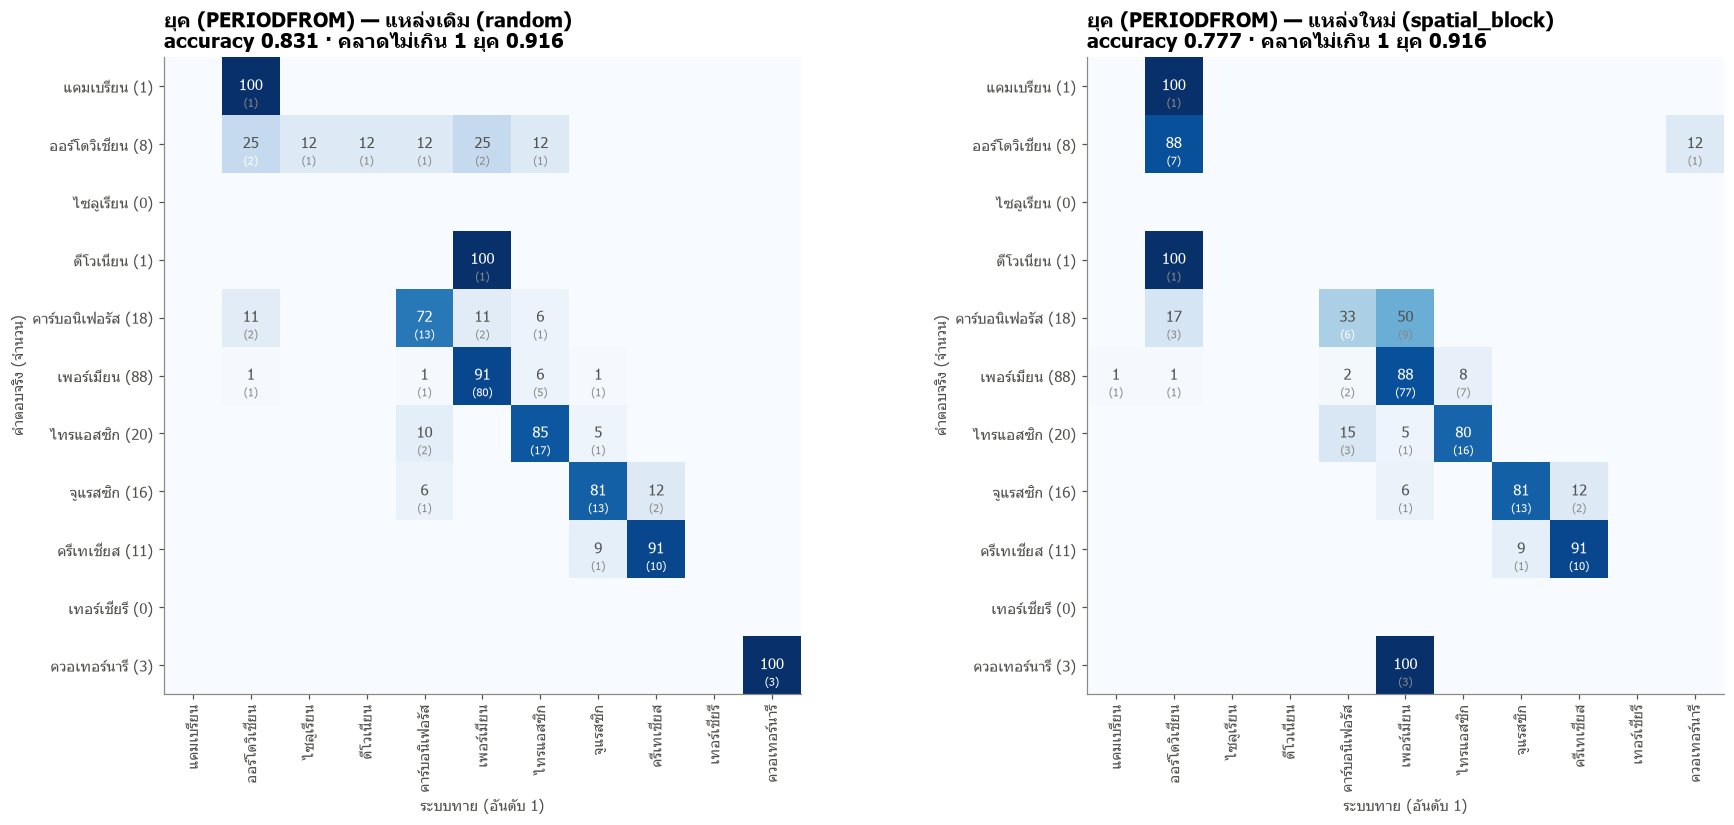

,แหล่ง,accuracy รวมทุก fold,within-1 รวมทุก fold,accuracy เฉลี่ยต่อ fold (หัวข้อ 4)
cv,,,,
random,166,0.831,0.916,0.830
spatial_block,166,0.777,0.916,0.719


In [13]:
# ---- ยุค (PERIODFROM): LightGBM +surface วัดบนแหล่งที่ ทธ. บันทึกยุค
LAB_P = [fl.PERIOD_TH_NAME[p] for p in PERIODS]
fig, axes = plt.subplots(1, 2, figsize=(17, 7.6))
rows = []
for ax, cv in zip(axes, ["random", "spatial_block"]):
    o = regP.oof(f"{cv}__lgbm@+surface")
    o = o[o.point_id.isin(recorded_ids)]
    pc = [c for c in o.columns if c.startswith("p_")]
    y, pred = o.y.values, o[pc].values.argmax(1)
    cm = confusion_matrix(y, pred, labels=range(len(PERIODS)))
    pd.DataFrame(cm, index=LAB_P, columns=LAB_P).rename_axis("จริง \\ ทาย").to_csv(CM_DIR / f"periodfrom_{cv}.csv", encoding="utf-8-sig")
    rank = np.array([fl.PERIOD_ORDER.index(p) for p in PERIODS])
    acc, w1 = (y == pred).mean(), (np.abs(rank[y] - rank[pred]) <= 1).mean()
    rows.append({"cv": cv, "แหล่ง": len(y), "accuracy รวมทุก fold": acc, "within-1 รวมทุก fold": w1,
                 "accuracy เฉลี่ยต่อ fold (หัวข้อ 4)": tP.loc["+surface", ("acc", cv)]})
    plot_cm(ax, cm, LAB_P, f"ยุค (PERIODFROM) — {CV_TH[cv]}\naccuracy {acc:.3f} · คลาดไม่เกิน 1 ยุค {w1:.3f}", fs=10, annot_min=0.1)
    for i, j in zip(*np.nonzero(cm)):                 # จำนวนแหล่งใต้ร้อยละ
        ax.text(j, i + 0.3, f"({cm[i, j]})", ha="center", va="center", fontsize=7, color=MUTED if i != j else "white")
plt.tight_layout()
fig.savefig(FIG_DIR / "confusion_periodfrom.png", dpi=200, bbox_inches="tight")
plt.show()
display(pd.DataFrame(rows).set_index("cv").style.format({c: "{:.3f}" for c in rows[0] if c not in ("cv", "แหล่ง")}))

## 9. ความไวต่อจำนวนมิติของคุณลักษณะข้อความ

TF-IDF ลดมิติด้วย TruncatedSVD และ WangchanBERTa ด้วย PCA เหลือ **32 มิติ** ซึ่งตั้งตามหลักการ ไม่ได้ปรับจากข้อมูล
(เท่ากันทุกตัวแทนข้อความเพื่อให้เทียบกันได้ และไม่ให้ข้อความมีคอลัมน์มากกว่ากลุ่มอื่น) ส่วนนี้ลอง **16 / 64 / 128 มิติ**
กับแบบจำลองเต็มของเส้นทางที่ใช้ข้อความนั้นจริง แล้ววัดเป็น**ระบบ** (สลับตามกรณี + ตัวกรองความสอดคล้อง) บน fold ชุดเดียวกับ 32 มิติ

- **TF-IDF → SVD**: เส้นทางแหล่งเดิม (`xgb` + TF-IDF) วัดที่ `random` (แหล่งเดิม)
- **WangchanBERTa → PCA**: เส้นทางแหล่งใหม่ (`lgbm` + หมวดหิน + BERT) วัดที่ `spatial_block` (แหล่งใหม่)
- อีกเส้นทางคงเป็นแบบจำลองที่ใช้จริง (32 มิติ) และ Δ คือผลต่างรายรอบเทียบกับ 32 มิติ
- `kept_var` = สัดส่วนความแปรปรวนที่ตัวลดมิติเก็บไว้ (เฉลี่ยจากการ fit บนชุดฝึกของแต่ละรอบ)

ส่วนนี้ไม่เปลี่ยนแบบจำลองที่ใช้จริง

In [14]:
DIMS = [16, 32, 64, 128]
for dim in DIMS:
    if dim != TXT_DIM:
        ADD[f"combo_known_d{dim}"] = ([f"@tfidf#{dim}"], [])
        ADD[f"combo_new_d{dim}"] = (FM_COLS["formation_only"][0] + [f"@wangchanberta#{dim}"], FM_COLS["formation_only"][1])
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
for dim in ml.tqdm_auto()([d for d in DIMS if d != TXT_DIM], desc="จำนวนมิติ"):
    run_g(regG, "known", "random", f"combo_known_d{dim}", model="xgb")
    run_g(regG, "new", "spatial_block", f"combo_new_d{dim}", model="lgbm")


def kept_var(kind, dim, cv):
    txt = text_of(lab).values
    out = []
    for k in range(ml.N_FOLDS):
        tr = lab[f"fold_{cv}"].values != k
        if kind == "tfidf":
            X = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True).fit_transform(txt[tr])
            out.append(TruncatedSVD(dim, random_state=0).fit(X).explained_variance_ratio_.sum())
        else:
            out.append(PCA(dim, random_state=0).fit(fl.text_embed(txt[tr], kind)).explained_variance_ratio_.sum())
    return float(np.mean(out))


exp_k = lambda d: "known__random__xgb@combo_known" + ("" if d == TXT_DIM else f"_d{d}")
exp_n = lambda d: "new__spatial_block__lgbm@combo_new" + ("" if d == TXT_DIM else f"_d{d}")
base_k = routed("random", (regG, exp_k(TXT_DIM)), (regG, "new__random__lgbm@combo_new"))
base_n = routed("spatial_block", (regG, "known__spatial_block__xgb@combo_known"), (regG, exp_n(TXT_DIM)))
rows = []
for d in DIMS:
    for name, r, b, kind, cv in [
            ("TF-IDF → SVD (แหล่งเดิม)", routed("random", (regG, exp_k(d)), (regG, "new__random__lgbm@combo_new")), base_k, "tfidf", "random"),
            ("WangchanBERTa → PCA (แหล่งใหม่)", routed("spatial_block", (regG, "known__spatial_block__xgb@combo_known"), (regG, exp_n(d))), base_n, "wangchanberta", "spatial_block")]:
        diff = r.acc - b.acc
        rows.append({"ตัวแทนข้อความ": name, "มิติ": d, "kept_var": kept_var(kind, d, cv), "acc": r.acc.mean(), "top3": r.top3.mean(),
                     "Δacc": diff.mean(), "SD": diff.std(), "ดีขึ้น (fold)": int((diff > 1e-12).sum()), "แย่ลง (fold)": int((diff < -1e-12).sum())})
tDim = pd.DataFrame(rows).set_index(["ตัวแทนข้อความ", "มิติ"])
tDim.reset_index().to_parquet(OUT / "text_dim_sensitivity.parquet", index=False)
display(tDim.style.format({"kept_var": "{:.1%}", "acc": "{:.3f}", "top3": "{:.3f}", "Δacc": "{:+.4f}", "SD": "{:.4f}"}))
for name, g in tDim.groupby(level=0):
    g = g.droplevel(0)
    print(f"{name}: acc {g.acc.min():.3f}–{g.acc.max():.3f} (32 มิติ {g.at[TXT_DIM, 'acc']:.3f}), "
          f"top-3 {g.top3.min():.3f}–{g.top3.max():.3f} (32 มิติ {g.at[TXT_DIM, 'top3']:.3f}), "
          f"ความแปรปรวนที่เก็บไว้ที่ 32 มิติ {g.at[TXT_DIM, 'kept_var']:.1%}")

new__spatial_block__lgbm@combo_new_d128:   0%|          | 0/1 [00:00<?, ?it/s]


,,kept_var,acc,top3,Δacc,SD,ดีขึ้น (fold),แย่ลง (fold)
ตัวแทนข้อความ,มิติ,,,,,,,
TF-IDF → SVD (แหล่งเดิม),16,66.9%,0.664,0.862,-0.0025,0.0043,2,3
WangchanBERTa → PCA (แหล่งใหม่),16,87.8%,0.400,0.591,+0.0037,0.0029,5,0
TF-IDF → SVD (แหล่งเดิม),32,79.9%,0.667,0.863,+0.0000,0.0000,0,0
WangchanBERTa → PCA (แหล่งใหม่),32,94.0%,0.396,0.587,+0.0000,0.0000,0,0
TF-IDF → SVD (แหล่งเดิม),64,88.9%,0.668,0.861,+0.0008,0.0040,1,2
WangchanBERTa → PCA (แหล่งใหม่),64,97.6%,0.397,0.587,+0.0006,0.0066,2,3
TF-IDF → SVD (แหล่งเดิม),128,95.0%,0.666,0.860,-0.0007,0.0032,2,3
WangchanBERTa → PCA (แหล่งใหม่),128,99.3%,0.398,0.580,+0.0014,0.0099,2,3


TF-IDF → SVD (แหล่งเดิม): acc 0.664–0.668 (32 มิติ 0.667), top-3 0.860–0.863 (32 มิติ 0.863), ความแปรปรวนที่เก็บไว้ที่ 32 มิติ 79.9%
WangchanBERTa → PCA (แหล่งใหม่): acc 0.396–0.400 (32 มิติ 0.396), top-3 0.580–0.591 (32 มิติ 0.587), ความแปรปรวนที่เก็บไว้ที่ 32 มิติ 94.0%


## 10. วิธีรวมเวกเตอร์ของ WangchanBERTa (pooling) และรูปแบบข้อความที่ป้อน

WangchanBERTa ให้เวกเตอร์ 768 มิติ**ต่อโทเค็น** จึงต้องรวมเป็นเวกเตอร์เดียวต่อข้อความก่อนลดเป็น PCA 32 มิติ ตัวที่ใช้จริงคือ **mean pooling**
(เฉลี่ยโทเค็นจริง ไม่นับ padding) ส่วนนี้เทียบกับ **`<s>`** (เวกเตอร์ของโทเค็นแรก แบบ CLS) และ **max pooling** (ค่าสูงสุดรายมิติ)

ระหว่างเตรียมการทดลองพบว่าข้อความบางแบบทำให้**เวกเตอร์ของทุกโทเค็นในชั้นสุดท้ายเกือบเท่ากัน** ("ยุบ" — SD รายมิติระหว่างโทเค็นใกล้ 0)
เช่น "ไดโนเสาร์ | ไดโนเสาร์ | ฟัน" ขณะที่ข้อความภาษาไทยทั่วไปไม่ยุบ — ตอน pretrain WangchanBERTa แทนช่องว่างด้วยโทเค็น `<_>`
แต่ระบบป้อนช่องว่างปกติ จึงทดลองทั้ง 2 รูปแบบข้อความ × 3 วิธีรวมเวกเตอร์ (6 แบบ) กับแบบจำลองเต็มของเส้นทางแหล่งใหม่
(`lgbm` + หมวดหิน + ข้อความ) วัดเป็น**ระบบ** (สลับตามกรณี + ตัวกรอง) ที่ `spatial_block` บน fold ชุดเดียวกับแบบที่ใช้จริง
— Δ = ผลต่างรายรอบเทียบแบบที่ใช้จริง (mean, ช่องว่างปกติ), F1 macro รวมทุก fold

ส่วนนี้ไม่เปลี่ยนแบบจำลองที่ใช้จริง

In [15]:
from sklearn.metrics import f1_score

# ---- ข้อความที่ "ยุบ" (ชั้นสุดท้าย: ทุกโทเค็นได้เวกเตอร์เกือบเท่ากัน)
allt = text_of(S)
uniq = allt.value_counts()
SPREAD = {sp: fl.token_spread(list(uniq.index), space_token=sp) for sp in [False, True]}
COLLAPSE = 0.05
for sp, s in SPREAD.items():
    c = s < COLLAPSE
    print(f"{'แทนช่องว่างด้วย <_>' if sp else 'ช่องว่างปกติ (ใช้จริง)'}: ข้อความที่ยุบ {c.sum():,} / {len(s):,} แบบ ({c.mean():.1%}) "
          f"= ตัวอย่าง {uniq.values[c].sum():,} / {uniq.sum():,} ชิ้น ({uniq.values[c].sum() / uniq.sum():.1%}) | SD มัธยฐาน {np.median(s):.3f}")
print("ตัวอย่างข้อความที่ยุบ:", list(uniq.index[SPREAD[False] < COLLAPSE][:5]))

# ---- 6 แบบ: รูปแบบข้อความ × วิธีรวมเวกเตอร์
POOL = [("wangchanberta", "ช่องว่างปกติ", "mean (ใช้จริง)"), ("wangchanberta_cls", "ช่องว่างปกติ", "<s>"), ("wangchanberta_max", "ช่องว่างปกติ", "max"),
        ("wangchanberta_sp", "แทนด้วย <_>", "mean"), ("wangchanberta_sp_cls", "แทนด้วย <_>", "<s>"), ("wangchanberta_sp_max", "แทนด้วย <_>", "max")]
for kind, _, _ in POOL[1:]:
    ADD[f"combo_new_{kind}"] = (FM_COLS["formation_only"][0] + [f"@{kind}"], FM_COLS["formation_only"][1])
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
for kind, _, _ in ml.tqdm_auto()(POOL[1:], desc="pooling"):
    run_g(regG, "new", "spatial_block", f"combo_new_{kind}", model="lgbm")

exp_p = lambda kind: "new__spatial_block__lgbm@combo_new" + ("" if kind == "wangchanberta" else f"_{kind}")
known_sb = (regG, "known__spatial_block__xgb@combo_known")
base_p = routed("spatial_block", known_sb, (regG, exp_p("wangchanberta")))
rows = []
for kind, form, pool in POOL:
    r = routed("spatial_block", known_sb, (regG, exp_p(kind)))
    yy, pp = zip(*[(y, P.argmax(axis=1)) for _, y, P in routed_folds("spatial_block", known_sb, (regG, exp_p(kind)))])
    diff = r.acc - base_p.acc
    rows.append({"ข้อความ": form, "pooling": pool, "kept_var": kept_var(kind, TXT_DIM, "spatial_block"), "acc": r.acc.mean(), "top3": r.top3.mean(),
                 "F1 macro": f1_score(np.concatenate(yy), np.concatenate(pp), average="macro", zero_division=0),
                 "Δacc": diff.mean(), "SD": diff.std(), "ดีขึ้น (fold)": int((diff > 1e-12).sum()), "แย่ลง (fold)": int((diff < -1e-12).sum())})
tPool = pd.DataFrame(rows).set_index(["ข้อความ", "pooling"])
tPool.reset_index().to_parquet(OUT / "text_pooling_sensitivity.parquet", index=False)
display(tPool.style.format({"kept_var": "{:.1%}", "acc": "{:.3f}", "top3": "{:.3f}", "F1 macro": "{:.3f}", "Δacc": "{:+.4f}", "SD": "{:.4f}"}))
best = tPool.top3.idxmax()
print(f"top-3 สูงสุด: {best[0]} / {best[1]} = {tPool.top3.max():.3f} (ใช้จริง {tPool.top3.iat[0]:.3f}); "
      f"accuracy {tPool.acc.min():.3f}–{tPool.acc.max():.3f}; F1 macro {tPool['F1 macro'].min():.3f}–{tPool['F1 macro'].max():.3f}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12503.99it/s]


ช่องว่างปกติ (ใช้จริง): ข้อความที่ยุบ 154 / 1,314 แบบ (11.7%) = ตัวอย่าง 1,933 / 8,521 ชิ้น (22.7%) | SD มัธยฐาน 0.732
แทนช่องว่างด้วย <_>: ข้อความที่ยุบ 0 / 1,314 แบบ (0.0%) = ตัวอย่าง 0 / 8,521 ชิ้น (0.0%) | SD มัธยฐาน 0.757
ตัวอย่างข้อความที่ยุบ: ['ไดโนเสาร์ | ไดโนเสาร์ | ฟัน', 'ไดโนเสาร์ | ไดโนเสาร์ | เศษกระดูก', 'ปลากระดูกอ่อน | ปลากระดูกอ่อน | ฟัน', 'ไดโนเสาร์ | ไดโนเสาร์ | กระดูกสันหลัง', 'สัตว์กินเนื้อ | สัตว์กินเนื้อ | ฟัน']


pooling: 100%|██████████| 5/5 [00:01<00:00,  2.83it/s]
new__spatial_block__lgbm@combo_new_wangchanberta_cls:   0%|          | 0/1 [00:00<?, ?it/s]
new__spatial_block__lgbm@combo_new_wangchanberta_max:   0%|          | 0/1 [00:00<?, ?it/s]
new__spatial_block__lgbm@combo_new_wangchanberta_sp:   0%|          | 0/1 [00:00<?, ?it/s]
new__spatial_block__lgbm@combo_new_wangchanberta_sp_cls:   0%|          | 0/1 [00:00<?, ?it/s]
new__spatial_block__lgbm@combo_new_wangchanberta_sp_max:   0%|          | 0/1 [00:00<?, ?it/s]


top-3 สูงสุด: แทนด้วย <_> / <s> = 0.597 (ใช้จริง 0.587); accuracy 0.391–0.404; F1 macro 0.118–0.127


## 11. สลับวิธีแทนข้อความระหว่างเส้นทาง (แบบจำลองเต็ม)

หัวข้อ 5 ทดสอบแบบจำลองเต็มเฉพาะ **TF-IDF ในเส้นทางแหล่งเดิม** และ **WangchanBERTa / MiniLM ในเส้นทางแหล่งใหม่** (ตามผลคัดกรองหัวข้อ 3)
ส่วนนี้เติมคู่ที่ยังไม่ได้ทดสอบ เพื่อตอบว่า "ใช้วิธีแทนข้อความเดียวกันทั้งสองเส้นทางได้ไหม"

- **แหล่งเดิม** (`xgb` + คุณลักษณะแหล่ง) + WangchanBERTa / + multilingual MiniLM แทน TF-IDF
- **แหล่งใหม่** (`lgbm` + หมวดหิน) + TF-IDF แทน WangchanBERTa
- วัดเป็น**ระบบ** (สลับตามกรณี + ตัวกรอง) แบบเดียวกับหัวข้อ 5: อีกเส้นทางเป็นระบบฐานของ notebook 11 — เทียบกับแบบที่ใช้จริงของเส้นทางเดียวกัน
  บน cv หลักของเส้นทางนั้น (แหล่งเดิม = `random`, แหล่งใหม่ = `spatial_block`); Δ = ผลต่างรายรอบ

ส่วนนี้ไม่เปลี่ยนแบบจำลองที่ใช้จริง

In [16]:
ADD["combo_known_bert"] = (["@wangchanberta"], [])
ADD["combo_known_mlm"] = (["@multilingual"], [])
ADD["combo_new_tfidf"] = (FM_COLS["formation_only"][0] + ["@tfidf"], FM_COLS["formation_only"][1])
ml.set_multiclass(len(GENERA))
ml.MC_CONTEXT.clear()
ml.MC_CONTEXT.update(classes=GENERA, ordinal=None)
for cv in ml.tqdm_auto()(["random", "spatial_block"], desc="สลับวิธีแทนข้อความ"):
    run_g(regG, "known", cv, "combo_known_bert", model="xgb")
    run_g(regG, "known", cv, "combo_known_mlm", model="xgb")
    run_g(regG, "new", cv, "combo_new_tfidf", model="lgbm")

SYS_X = [  # (เส้นทาง, ชื่อ, ฟังก์ชันคืน (known, new), เป็นแบบที่ใช้จริงไหม)
    ("แหล่งเดิม", "แหล่งเดิม + TF-IDF (ใช้จริง)", lambda cv: ((regG, f"known__{cv}__xgb@combo_known"), (REG_V3, f"{cv}__lgbm@specimen")), True),
    ("แหล่งเดิม", "แหล่งเดิม + WangchanBERTa", lambda cv: ((regG, f"known__{cv}__xgb@combo_known_bert"), (REG_V3, f"{cv}__lgbm@specimen")), False),
    ("แหล่งเดิม", "แหล่งเดิม + multilingual MiniLM", lambda cv: ((regG, f"known__{cv}__xgb@combo_known_mlm"), (REG_V3, f"{cv}__lgbm@specimen")), False),
    ("แหล่งใหม่", "แหล่งใหม่ + หมวดหิน + TF-IDF", lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new_tfidf")), False),
    ("แหล่งใหม่", "แหล่งใหม่ + หมวดหิน + WangchanBERTa (ใช้จริง)", lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new")), True),
    ("แหล่งใหม่", "แหล่งใหม่ + หมวดหิน + multilingual MiniLM", lambda cv: ((REG_V3, f"{cv}__xgb"), (regG, f"new__{cv}__lgbm@combo_new_mlm")), False),
]
MAIN_CV = {"แหล่งเดิม": "random", "แหล่งใหม่": "spatial_block"}
RX = {(name, cv): routed(cv, *f(cv)) for _, name, f, _ in SYS_X for cv in ["random", "spatial_block"]}
rows = []
for route, name, f, used in SYS_X:
    cv = MAIN_CV[route]
    ref = next(n for r_, n, _, u in SYS_X if r_ == route and u)
    d = RX[name, cv].acc - RX[ref, cv].acc
    rows.append({"เส้นทาง": route, "ระบบ": name,
                 "acc แหล่งเดิม": RX[name, "random"].acc.mean(), "top3 แหล่งเดิม": RX[name, "random"].top3.mean(),
                 "acc แหล่งใหม่": RX[name, "spatial_block"].acc.mean(), "top3 แหล่งใหม่": RX[name, "spatial_block"].top3.mean(),
                 "Δacc เทียบใช้จริง": d.mean(), "SD": d.std(), "Δtop3 เทียบใช้จริง": (RX[name, cv].top3 - RX[ref, cv].top3).mean(),
                 "ดีขึ้น (fold)": int((d > 1e-12).sum()), "แย่ลง (fold)": int((d < -1e-12).sum())})
tX = pd.DataFrame(rows).set_index(["เส้นทาง", "ระบบ"])
tX.reset_index().to_parquet(OUT / "text_route_cross.parquet", index=False)
display(tX.style.format({c: "{:.3f}" for c in tX.columns if tX[c].dtype.kind == "f" and not c.startswith(("Δ", "SD"))}
                        | {"Δacc เทียบใช้จริง": "{:+.4f}", "SD": "{:.4f}", "Δtop3 เทียบใช้จริง": "{:+.4f}"}))
for route, g in tX.groupby(level=0):
    g = g.droplevel(0); col = "แหล่งเดิม" if route == "แหล่งเดิม" else "แหล่งใหม่"
    print(f"{route}: " + " | ".join(f"{n} {g.at[n, f'acc {col}']:.3f} / {g.at[n, f'top3 {col}']:.3f}" for n in g.index))

new__spatial_block__lgbm@combo_new_tfidf:   0%|          | 0/1 [00:00<?, ?it/s]


แหล่งเดิม: แหล่งเดิม + TF-IDF (ใช้จริง) 0.668 / 0.861 | แหล่งเดิม + WangchanBERTa 0.668 / 0.859 | แหล่งเดิม + multilingual MiniLM 0.669 / 0.860
แหล่งใหม่: แหล่งใหม่ + หมวดหิน + TF-IDF 0.396 / 0.583 | แหล่งใหม่ + หมวดหิน + WangchanBERTa (ใช้จริง) 0.396 / 0.587 | แหล่งใหม่ + หมวดหิน + multilingual MiniLM 0.391 / 0.576


## สรุป

(ตัวเลขหลังตรวจทาน: label สกุลตัดชื่อระดับสูง / ชื่อเรียกระดับวงศ์ที่ลงท้าย -id (Stegosaurid, Pectinid) / แก้ชื่อสะกดผิด
และลบชื่อวิทยาศาสตร์ที่เขียนไว้ใน `f_part` ก่อนสร้าง feature ข้อความ)

**แก้บั๊ก embedding**: รอบก่อน embedding ของ BERT / multilingual อ่านจากไฟล์ `.npy` ตาม "ลำดับแถว" ที่สร้างไว้ก่อนแก้ `f_part`
(1,313 ข้อความ แต่ข้อความปัจจุบันมี 1,314) → ข้อความที่มีสกุลได้ embedding ของตัวเองแค่ 23.6% ที่เหลือเป็นของข้อความอื่น
ตอนนี้ดึงด้วย "ตัวข้อความ" (`feature_lib.text_embed`, ตัวเดียวกับโมเดลตัวจริง) และรันการทดลองที่ใช้ embedding ใหม่ทั้งหมด
(โมเดลตัวจริงใน notebook 11 ใช้ cache ที่ผูกกับตัวข้อความอยู่แล้วจึงไม่โดน; มีเทสต์ตรวจ cache กับค่าที่คำนวณสดแล้ว)

**คัดกรองทีละกลุ่ม** (`lgbm_fast`, accuracy + ตัวกรองความสอดคล้อง; Δ เทียบ base)

| กลุ่มที่เพิ่ม | แหล่งเดิม (`random`, base 0.593) | แหล่งใหม่ (`spatial_block`, base 0.355) |
|---|---|---|
| หมวดหิน Impute+Flag | +0.005 | +0.012 |
| หมวดหิน Impute only | +0.003 | **+0.043** |
| ส่วนของซาก (`f_part`) | +0.006 | +0.027 |
| TF-IDF | +0.018 | +0.026 |
| WangchanBERTa | +0.014 | +0.019 |
| multilingual MiniLM | **+0.019** | +0.016 |
| บริบทสกุล (out-of-fold) | +0.008 | −0.054 |
| PBDB ใกล้เคียง | −0.001 | −0.058 |

- **ข้อความช่วยทั้งสองเส้นทาง**: ที่แหล่งเดิม TF-IDF กับ multilingual ใกล้กันมาก (ระดับ noise); ที่แหล่งใหม่ BERT ดีกว่า multilingual เล็กน้อย
  — รอบก่อนลบชื่อวิทยาศาสตร์ใน `f_part` BERT ได้ +0.031 ที่แหล่งใหม่ ส่วนหนึ่งจึงมาจากการเห็นชื่อสกุลในข้อความ
- **หมวดหินช่วยเฉพาะแหล่งใหม่** (โมเดลจำแหล่งไม่ได้จึงพึ่งหมวดหิน); แบบ Impute only ดีกว่า Impute+Flag
- **บริบทสกุลและ PBDB ใกล้เคียงทำให้แหล่งใหม่แย่ลง** — สกุลของแหล่งอื่นในบล็อกอื่นชี้ผิดทาง
- **ยุค**: ไม่มีกลุ่มไหนช่วยสม่ำเสมอ; `FORMATION` ที่ ทธ. บันทึกดูดี (0.729) แต่เมื่อซ่อนของแหล่งทดสอบเหลือ 0.697 < base 0.704
  เพราะบันทึกคู่กับยุค (มีใน 84% ของแหล่งที่มียุค แต่ 9% ของแหล่งที่ต้องเติม) → ไม่ใช้; `+surface` ได้ 0.719

**ชุดรวมด้วยโมเดลเต็ม** (ระบบสลับตามกรณี + ตัวกรอง เทียบระบบฐานของ notebook 11 บน fold เดียวกัน; acc / top-3)

| ระบบ | แหล่งเดิม (`random`) | แหล่งใหม่ (`spatial_block`) |
|---|---|---|
| ระบบฐาน notebook 11 (ไม่มีข้อความ / หมวดหิน) | 0.656 / 0.859 | 0.396 / 0.546 |
| แหล่งเดิม + TF-IDF | **0.668** / 0.861 (ดีขึ้น 5/5 fold) | 0.396 / 0.546 |
| แหล่งใหม่ + หมวดหิน (ไม่มีข้อความ) | 0.655 / 0.859 | **0.412** / 0.566 (ดีขึ้น 3/5 fold) |
| แหล่งใหม่ + หมวดหิน + BERT | 0.654 / 0.860 | 0.396 / **0.587** (ดีขึ้น 2/5 fold) |
| แหล่งใหม่ + หมวดหิน + multilingual | 0.655 / 0.860 | 0.391 / 0.576 (ดีขึ้น 1/5 fold) |
| **ชุดรวมทั้งสองเส้นทาง (TF-IDF + หมวดหิน + BERT, ใช้จริง)** | **0.667 / 0.863** | **0.396 / 0.587** |

**ตกลงหลังดูผล**: แหล่งเดิมใช้ TF-IDF; แหล่งใหม่ใช้หมวดหิน + ข้อความตามกติกา "ลอง BERT ก่อน ถ้าไม่ดีกว่าใช้ multilingual"
— หลังแก้บั๊ก BERT ดีกว่า multilingual ทั้ง acc และ top-3 จึงใช้ BERT (notebook 11 → `genus_v7_*`, notebook 12) และยุคใช้ `+surface`;
หลังแก้ป้าย -id แล้วรันใหม่ BERT ยังดีกว่า multilingual ทั้งสองค่า
- ที่แหล่งใหม่ความต่างทุกแบบอยู่ในระดับ noise (SD ของ Δacc ระหว่าง fold ราว 0.06–0.08): หมวดหินอย่างเดียวได้ accuracy สูงสุด
- **สลับวิธีแทนข้อความระหว่างเส้นทาง (หัวข้อ 11)**: แหล่งเดิม TF-IDF 0.668 / 0.861 (ใช้จริง), WangchanBERTa 0.668 / 0.859, multilingual 0.669 / 0.860; แหล่งใหม่ (+ หมวดหิน) TF-IDF 0.396 / 0.583, WangchanBERTa 0.396 / 0.587 (ใช้จริง), multilingual 0.391 / 0.576 — ต่างกันในระดับ noise ทั้งสองเส้นทาง: ใช้ TF-IDF ทั้งสองเส้นทางก็ได้ผลแทบเท่าเดิม (แหล่งใหม่ top-3 ลดเพียงเล็กน้อย, accuracy แย่ลง 4/5 fold แต่ไม่ถึงระดับ noise); คงแบบที่ใช้จริงตามกติกาเดิม
- **WangchanBERTa: วิธีรวมเวกเตอร์ + รูปแบบข้อความ (หัวข้อ 10)**: ป้อนช่องว่างปกติแล้วข้อความ 154 / 1,314 แบบ (ตัวอย่าง 1,933 / 8,521 ชิ้น) ได้เวกเตอร์ทุกโทเค็นเกือบเท่ากัน ("ยุบ") เช่น "ไดโนเสาร์ | ไดโนเสาร์ | ฟัน"; แทนช่องว่างด้วย `<_>` (รูปแบบตอน pretrain) แล้วไม่ยุบเลย — แต่ผลทั้ง 6 แบบ (2 รูปแบบข้อความ × mean / `<s>` / max) ใกล้กันมาก: accuracy 0.391–0.404, F1 macro 0.118–0.127; top-3 สูงสุดคือ `<_>` + `<s>` 0.597 (ใช้จริง 0.587, ดีขึ้น 4/5 fold แย่ลง 0) — ต่างในระดับ noise จึงยังไม่เปลี่ยนแบบที่ใช้จริง
  แต่ BERT ให้ top-3 สูงสุด ซึ่งตรงกับการใช้งาน (เสนอชื่อ 3 อันดับให้ผู้เชี่ยวชาญตรวจ) — รอบนี้ accuracy ของชุดรวมที่แหล่งใหม่เท่าระบบฐาน
  (0.396) ส่วน top-3 ดีขึ้น 0.546 → 0.587

**เส้นทางพิกัดใหม่** (หัวข้อ 6; ระบบแหล่งใหม่ `spatial_block`, acc / top-3): หมวดหินจากแผนที่ธรณีตรงกับที่ ทธ. บันทึกแค่ 19%
(ของตัวอย่างที่มีบันทึก) แต่ใช้แทนกันได้เกือบเท่าเดิม — บันทึก 0.396 / 0.587, แผนที่ 0.396 / 0.584, ไม่ใส่ 0.377 / 0.570
(เฉพาะแหล่งที่บันทึกหมวดหิน: 0.289 / 0.588, 0.278 / 0.579, 0.248 / 0.557) → notebook 12 ใช้หมวดหินจากแผนที่สำหรับพิกัดใหม่ต่อไปได้

**ทายสกุลเมื่อผู้ใช้ไม่รู้ประเภทซาก** (หัวข้อ 7; ระบบที่ใช้จริง, top-3 out-of-fold ด้วยโมเดลของ fold เดิม; แบบบอกหน้าตานับตามที่เว็บแสดง
คือ "ยังระบุชื่อไม่ได้" แยกเป็นรายการตามกลุ่มซาก — วงเล็บ = ถ้ารวม "อื่น ๆ" เป็นรายการเดียว)

| ข้อมูลที่ผู้ใช้ให้ | แหล่งเดิม (`random`) | แหล่งใหม่ (`spatial_block`) |
|---|---|---|
| ทะเบียนจริง (ประเภท + ชื่อที่เรียก + ส่วนของซาก) | 0.863 | 0.587 |
| รู้ประเภท แต่ไม่มีชื่อที่เรียก (ทางลัด "เลือกประเภทเอง") | 0.820 | 0.585 |
| บอกหน้าตา + ตอบคำถามต่อ | 0.723 (0.733) | 0.472 (0.487) |
| บอกหน้าตา แค่รูปแรก (คำถามต่อตอบ "ไม่แน่ใจ") | 0.586 (0.628) | 0.374 (0.410) |
| เลือก "ไม่ตรงกับแบบไหน" (ระบบเดาจากสถิติทั้งหมด) | 0.304 (0.404) | 0.154 (0.214) |
| **ไม่บอกที่พบ** (ไม่มีจังหวัด / แหล่ง / หมวดหิน): ทะเบียนจริง | 0.662 | 0.536 |
| ไม่บอกที่พบ: รู้ประเภท ไม่มีชื่อที่เรียก | 0.587 | 0.530 |
| ไม่บอกที่พบ: บอกหน้าตา + ตอบคำถามต่อ | 0.499 (0.510) | 0.465 (0.477) |
| ไม่บอกที่พบ: บอกหน้าตา แค่รูปแรก | 0.421 (0.459) | 0.410 (0.445) |
| ไม่บอกที่พบ: เลือก "ไม่ตรงกับแบบไหน" | 0.227 (0.250) | 0.154 (0.193) |

- **แยก "ยังระบุชื่อไม่ได้" ตามกลุ่มซาก** (เช่น "ไดโนเสาร์ที่ยังระบุชื่อไม่ได้" กับ "ปลาที่ยังระบุชื่อไม่ได้"; กลุ่มเดียวกับตัวกรองความสอดคล้อง
  จึงรวมชื่อที่สะกดต่างกัน เช่น ไดโนเสาร์ + ซอโรพอด) บอกผู้ใช้ได้ว่าน่าจะเป็นซากกลุ่มไหน แต่ความน่าจะเป็นของ "อื่น ๆ" ถูกแบ่งหลายรายการ
  จึงหลุด 3 อันดับง่ายขึ้น: ตอบคำถามต่อลดราว 1–1.5 จุด, แค่รูปแรกลดราว 4 จุด, "ไม่ตรงกับแบบไหน" ลดมากสุด (แหล่งเดิม 0.404 → 0.304)
- การนับแบบแยกใช้อันดับแบบระวัง: ค่าเท่ากันนับว่าแพ้ และคำตอบที่ความน่าจะเป็น 0 ไม่นับว่าถูก (รอบแรกนับแบบ `>` ทำให้รอยตีนที่แหล่งใหม่ได้ 1.000
  ทั้งที่ทะเบียนจริงได้ 0.000) — ตรวจแล้วว่า top-3 หลัก (G1 / G2) ไม่มีกรณีที่นับถูกทั้งที่ความน่าจะเป็นเป็น 0
- จากหน้าตา ระบบให้น้ำหนักสูงสุดกับประเภทที่ถูก 80% / 78% และประเภทจริงอยู่ในชุดที่รวม 98% / 98% (ตอบคำถามต่อ);
  เลือก "ไม่ตรงกับแบบไหน" ถูกแค่ 20% / 18% จึงแม่นน้อยที่สุด
- **ไม่บอกที่พบ**: แหล่งเดิมลดมาก (บอกหน้าตา 0.723 → 0.499) เพราะเส้นทางแหล่งเดิมพึ่งข้อมูลของแหล่ง ส่วนแหล่งใหม่แทบไม่ต่าง
  (0.472 vs 0.465) — เว็บบอกตัวเลขของเส้นทางที่ผู้ใช้เลือกจริง (ไม่บอกที่พบใช้ตัวเลข `spatial_block` ซึ่งระมัดระวังกว่า) และชวนให้บอกที่พบ
- "ส่วนของซาก" ที่ป้อนโมเดลใช้**คำกลางของการ์ด** (เช่น "ฟัน") ดีกว่าคำที่ทะเบียนเขียนบ่อยสุด (แหล่งใหม่ 0.472 vs 0.404) และดีกว่าไม่ใส่
- รอบแรกการ์ดปลาใส่คำว่า "เกล็ดปลา" ให้ทุกตัว ปลาที่แหล่งใหม่ทายถูกไม่ถึง 5 ใน 100 เพราะปลา *Thaiichthys* ในทะเบียนส่วนใหญ่ไม่ระบุส่วน
  → แยกคำถามต่อ (เกล็ด / รอยตัวปลา / กระดูกหัว / ไม่แน่ใจ = ไม่ใส่) และตัวอย่างที่ทะเบียนไม่ได้บอกส่วนให้จำลองว่าผู้ใช้ตอบ "ไม่แน่ใจ" → 0.639
- คำตอบคำถามต่อต้องไปถึงโมเดล: ตัวเลือกที่ได้ชุดประเภทเดียวกัน (กระดูกแต่ละส่วน, ขดแบน = แอมโมไนต์ / แท่งมีห้อง = นอติลอยด์)
  ใช้คำบรรยายของตัวเอง ส่วนตัวเลือกที่ประเภทต่างกันอยู่แล้วใช้คำกลางของการ์ด (คำเจาะจงทำให้เปลือกสองฝาที่แหล่งใหม่แย่ลง)
  — กระดูกตอนนี้ได้ 0.816 / 0.643
- จุดอ่อนที่สุดคือ**ฟัน**ที่แหล่งใหม่ (0.337 vs ทะเบียนจริง 0.435): ฟันเป็นได้หลายกลุ่มและรูปร่างฟันแยกไดโนเสาร์กับฉลามได้ไม่ขาด
- ข้อควรระวัง: คำถามและวิธีเติมส่วนของซากปรับโดยดูผลชุดนี้ (เลือก 1 ใน 3 วิธี + แยกการ์ดปลา) ตัวเลขจึงอาจสูงกว่าการใช้งานจริงเล็กน้อย